# Thực nghiệm Minh họa (Demo 1) — MultiDelete trên Flickr30K: Tách rời Liên kết Đa phương thức (Modality Decoupling)

Notebook này cung cấp thực nghiệm minh họa định tính và định lượng cho bài báo **"MultiDelete for Multimodal Machine Unlearning"** (Cheng & Amiri, ECCV 2024) trên kiến trúc **ALBEF** với tác vụ **Truy hồi Văn bản - Ảnh (Image-Text Retrieval)**.

Với mỗi câu truy vấn văn bản $T_i$, hệ thống trích xuất danh sách ảnh ứng viên hàng đầu (Top-$K$) **trước khi quên** (Mô hình gốc $f$) và **sau khi quên** (Mô hình đã học quên $f'$ bằng thuật toán `MultiDelete`):
* **Trên tập dữ liệu xóa $\mathcal{D}_f$ (Deletion Set):** Quan sát tác động của **Modality Decoupling ($\mathcal{L}_{MD}$)** và **Unimodal Knowledge Retention ($\mathcal{L}_{UKR}$)** lên thứ hạng của ảnh đích $I_i$ (viền xanh lá), và các ảnh không liên quan (viền đỏ) thay thế nó.
* **Trên tập dữ liệu giữ lại $\mathcal{D}_r$ (Remaining Set - Đối chứng):** Quan sát mức độ giữ lại hiệu năng truy hồi nhờ **Multimodal Knowledge Retention ($\mathcal{L}_{MKR}$)**; thứ hạng trên $\mathcal{D}_r$ cũng có thể giảm nhẹ.

**Thời gian thực thi dự kiến:** Lần chạy đầu tiên cần thực hiện quá trình unlearning để thu được trọng số mô hình $f'$, mất khoảng **40 phút trên GPU NVIDIA T4** (Colab). Trọng số sau đó được lưu trữ bền vững trên Google Drive để các phiên làm việc tiếp theo có thể suy luận trực tiếp. Nếu đã có sẵn file trọng số, hãy khai báo biến `CKPT_SRC` tại **§0** để bỏ qua bước huấn luyện.

**Yêu cầu phần cứng:** `Runtime` → `Change runtime type` → **T4 GPU**.

| Phân mục | Nội dung thực thi |
|---|---|
| **§0** | Cấu hình tham số thực nghiệm, kết nối Google Drive và chuẩn bị tập dữ liệu Flickr30K |
| **§0b** | Khởi tạo 3 tệp mã nguồn thực thi (`multidelete.py`, `run_md_retrieval.py`, `demo1_engine.py`) |
| **§1** | Cài đặt môi trường phụ thuộc, sao chép mã nguồn LAVIS/MultiDelete và áp dụng bản vá tương thích |
| **§2** | Thực thi huấn luyện Unlearning (nếu chưa có checkpoint) và chạy đánh giá truy hồi Demo 1 |
| **§3** | Hiển thị trực quan kết quả truy hồi (`demo1.png`), biểu đồ dịch chuyển hạng (`demo1_rank_shift.png`) và bảng độ đo |

**Phạm vi của demo (đọc trước khi trích số liệu):** kho ảnh truy hồi chỉ gồm 1000 ảnh $\mathcal{D}_f$ và 1000 ảnh $\mathcal{D}_r$ ngẫu nhiên (2000 ảnh); thống kê trên 200 truy vấn mỗi nhóm; truy vấn lấy từ dữ liệu huấn luyện, không phải tập kiểm tra; một seed. Vì vậy các số R@K ở đây **không so được** với Bảng kết quả trong báo cáo và chỉ có tính minh hoạ, không thay cho đánh giá đầy đủ (Test TR/IR, Df-AUC) của `multidelete.py flickr30k`. Notebook này tự chứa 3 tệp `.py` ở §0b và không phụ thuộc `MultiDelete_all.ipynb`.

## §0. Cấu hình Tham số Thực nghiệm & Dữ liệu

Điều chỉnh đường dẫn `DRIVE_ROOT` và `FLICKR_SRC` tương ứng với cấu trúc thư mục trên Google Drive của bạn; các siêu tham số đánh giá ở cuối khối mã có thể giữ nguyên theo cấu hình chuẩn.

In [5]:
import os, sys, shutil, subprocess


DRIVE_ROOT = "/content/drive/MyDrive/Flickr30k"
FLICKR_SRC = "/content/drive/MyDrive/Flickr30k/flickr30k-images.tar.gz"

DEMO_PROFILE = "fast"
DEMO_N = 3
DEMO_CTRL = 2
DEMO_TOPK = 4
DEMO_NSTAT = 200
DEMO_PICK = "random"
DEMO_CAPTION = ""
CKPT_SRC = ""

SAVE = f"{DRIVE_ROOT}/multidelete_out"
PERSIST_CKPT = True
WORK = "/content/work"
CODE_DIR = "/content/md_code"
LOCAL_IMG = "/content/flickr30k_local"

from google.colab import drive
drive.mount("/content/drive")
os.makedirs(CODE_DIR, exist_ok=True); os.makedirs(SAVE, exist_ok=True); os.makedirs(WORK, exist_ok=True)
assert DEMO_PROFILE in ("fast", "smoke"), "DEMO_PROFILE phải là fast hoặc smoke"


def find_flickr_dir(root):
    for dp, dn, fn in os.walk(root):
        if "1000092795.jpg" in fn and sum(f.endswith(".jpg") for f in fn) > 30000:
            return dp
    return None


def prepare_flickr(src, dst):
    """Đưa ảnh Flickr30K từ Drive sang đĩa local (đọc từng ảnh trực tiếp từ Drive rất chậm). Trả về thư mục chứa ảnh."""
    assert os.path.exists(src), f"Không thấy {src} trên Drive. Kiểm tra lại FLICKR_SRC."
    got = find_flickr_dir(dst) if os.path.isdir(dst) else None
    if got:
        print("ảnh local đã có:", got); return got
    os.makedirs(dst, exist_ok=True)
    if src.endswith((".tar.gz", ".tgz")):
        print("giải nén", src, "-> đĩa local (vài phút)...")
        subprocess.run(["tar", "-xf", src, "-C", dst], check=True)
    elif src.endswith(".zip"):
        print("giải nén", src, "-> đĩa local (vài phút)...")
        subprocess.run(["unzip", "-q", "-o", src, "-d", dst], check=True)
    else:
        print("sao chép", src, "-> đĩa local (vài phút)...")
        subprocess.run(["cp", "-r", src.rstrip("/") + "/.", dst], check=True)
    got = find_flickr_dir(dst)
    assert got, "Không tìm thấy thư mục có 1000092795.jpg và > 30000 ảnh .jpg sau khi chuẩn bị. Kiểm tra nội dung FLICKR_SRC."
    return got


FLICKR_IMAGES = ""
if FLICKR_SRC:
    FLICKR_IMAGES = prepare_flickr(FLICKR_SRC, LOCAL_IMG)
    print("FLICKR_IMAGES =", FLICKR_IMAGES)
else:
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    except Exception as e:
        print("Chưa có Colab Secrets KAGGLE_USERNAME / KAGGLE_KEY:", repr(e)[:120])

if PERSIST_CKPT:
    ck_drive = f"{DRIVE_ROOT}/checkpoints"
    os.makedirs(ck_drive, exist_ok=True)
    link = f"{WORK}/checkpoints"
    if not os.path.lexists(link):
        os.symlink(ck_drive, link)
os.makedirs(f"{WORK}/checkpoints", exist_ok=True)

# checkpoint có sẵn: sao vào đúng tên mà `demo1` tìm (không huấn luyện lại)
CKPT_NAME = f"demo_multidelete_albef_df{1000 if DEMO_PROFILE == 'fast' else 100}_s42_ckpt.pth"
CKPT_DST = f"{WORK}/checkpoints/{CKPT_NAME}"
if CKPT_SRC:
    assert os.path.isfile(CKPT_SRC), f"Không thấy {CKPT_SRC}"
    if not os.path.exists(CKPT_DST):
        shutil.copyfile(CKPT_SRC, CKPT_DST)
    print("dùng checkpoint có sẵn:", CKPT_DST)
elif os.path.exists(CKPT_DST):
    print("đã có checkpoint từ phiên trước:", CKPT_DST, "-> không huấn luyện lại")
else:
    print("chưa có checkpoint -> §2 sẽ huấn luyện MultiDelete trước (~40 phút ở profile fast)")

os.chdir(CODE_DIR)
COMMON = f"--work {WORK} --save {SAVE}" + (f" --flickr-images {FLICKR_IMAGES}" if FLICKR_IMAGES else "")
try:
    print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.strip() or "KHÔNG thấy GPU: chọn Runtime -> T4 GPU")
except FileNotFoundError:
    print("KHÔNG thấy GPU: chọn Runtime -> Change runtime type -> T4 GPU")
print("WORK =", WORK, "\nSAVE =", SAVE, "\nCOMMON =", COMMON)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ảnh local đã có: /content/flickr30k_local/flickr30k-images
FLICKR_IMAGES = /content/flickr30k_local/flickr30k-images
đã có checkpoint từ phiên trước: /content/work/checkpoints/demo_multidelete_albef_df1000_s42_ckpt.pth -> không huấn luyện lại
GPU 0: Tesla T4 (UUID: GPU-664a5193-5540-7569-f203-61075b610f6c)
WORK = /content/work 
SAVE = /content/drive/MyDrive/Flickr30k/multidelete_out 
COMMON = --work /content/work --save /content/drive/MyDrive/Flickr30k/multidelete_out --flickr-images /content/flickr30k_local/flickr30k-images


## §0b. Khởi tạo Mã nguồn Thực thi

Ba khối mã dưới đây trích xuất 3 tệp `.py` vào thư mục `/content/md_code`: `multidelete.py` (trình điều phối thực nghiệm), `run_md_retrieval.py` (hiện thực hóa thuật toán MultiDelete và các hàm mất mát $\mathcal{L}_{MD}, \mathcal{L}_{MKR}, \mathcal{L}_{UKR}$), và `demo1_engine.py` (truy hồi hai giai đoạn ITC+ITM và kết xuất đồ thị đánh giá).

In [6]:
%%writefile /content/md_code/multidelete.py

"""
multidelete.py  -  Trình điều phối tái lập thực nghiệm MultiDelete (Cheng & Amiri, ECCV 2024)
Kiến trúc nền tảng: ALBEF | Tập dữ liệu: Flickr30K (Image-Text Retrieval) & NLVR2 (Visual Reasoning)
"""
import argparse
import csv
import json
import os
import re
import shutil
import subprocess
import sys
import time
import urllib.request

HERE = os.path.dirname(os.path.abspath(__file__))
REPO_URL = "https://github.com/CLU-UML/MultiDelete.git"
BACKBONE = "albef"
CFG = f"configs/original/{BACKBONE}/retrieval_flickr30k.yaml"

PIP_PACKAGES = [
    "transformers==4.36.2", "tokenizers>=0.14,<0.19", "timm==0.9.16",
    "omegaconf", "iopath", "einops", "ftfy", "fairscale", "webdataset", "contexttimer", "pycocoevalcap",
    "pycocotools", "sentencepiece", "scikit-learn", "pandas", "matplotlib", "opencv-python-headless",
    "datasets", "pyarrow", "kaggle",
]

# Cấu hình siêu tham số theo profile cho Flickr30K.
FLICKR_PROFILES = {
    "smoke": dict(df=100, epochs=1, k_test=8, bs=8, max_steps=25),      # Kiểm thử luồng thực thi (~30 phút)
    "fast": dict(df=1000, epochs=3, k_test=16, bs=16, max_steps=0),     # Cấu hình rút gọn cho báo cáo trên GPU T4
    "paper": dict(df=1000, epochs=5, k_test=128, bs=16, max_steps=0),   # Cấu hình đầy đủ theo bài báo gốc
}
NLVR2_PROFILES = ("smoke", "fast", "paper", "full")

FLICKR_ORDER = ["original", "main", "itc", "negdr", "noMD", "noMKR", "noUKR", "ft", "neggrad", "dtd"]
FLICKR_OPTIONAL = ["mdF", "neggradraw"]


def log(*a):
    print("[MultiDelete]", *a, flush=True)


# ----------------------------------------------------------------------------------------------------------
# Quản lý đường dẫn và tiến trình con
# ----------------------------------------------------------------------------------------------------------
class Paths:
    def __init__(self, a):
        self.work = os.path.abspath(a.work)
        self.save = os.path.abspath(a.save)
        self.repo = f"{self.work}/MultiDelete"
        self.cache = f"{self.work}/lavis_cache"
        self.stubs = f"{self.work}/stubs"
        self.ckpts = f"{self.work}/checkpoints"
        self.fl_results = f"{self.save}/flickr30k/results"
        self.fl_logs = f"{self.save}/flickr30k/logs"
        self.nl_root = f"{self.save}/nlvr2"
        self.demo_out = f"{self.save}/flickr30k/demo"


def make_env(P):
    env = dict(os.environ)
    env.update({
        "TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD": "1",
        "TOKENIZERS_PARALLELISM": "false",
        "WANDB_MODE": "disabled",
        "PYTORCH_CUDA_ALLOC_CONF": "expandable_segments:True",
        "PYTHONUNBUFFERED": "1",
    })
    env["PYTHONPATH"] = os.pathsep.join([P.stubs, P.repo, env.get("PYTHONPATH", "")])
    return env


def run_logged(cmd, name, P, logdir, cwd=None, check=True, echo_keys=(), dry=False):
    """Thực thi lệnh hệ thống, lưu toàn bộ nhật ký vào logdir/name.log và trích xuất các dòng chứa echo_keys."""
    os.makedirs(logdir, exist_ok=True)
    shown = cmd if isinstance(cmd, str) else " ".join(cmd)
    if dry:
        print(f"  $ (cwd={cwd}) {shown}")
        return 0
    path = f"{logdir}/{name}.log"
    t0 = time.time()
    log(f"{name}: bắt đầu thực thi (nhật ký: {path})")
    with open(path, "w", encoding="utf-8") as lf:
        p = subprocess.Popen(cmd, cwd=cwd, env=make_env(P), shell=isinstance(cmd, str), stdout=subprocess.PIPE,
                             stderr=subprocess.STDOUT, text=True, bufsize=1, encoding="utf-8", errors="replace")
        for line in p.stdout:
            lf.write(line)
            if echo_keys and any(k in line for k in echo_keys):
                print("   ", line.rstrip()[:300], flush=True)
        p.wait()
    log(f"{name}: hoàn tất (returncode={p.returncode}, thời gian={(time.time() - t0) / 60:.1f} phút)")
    if p.returncode and check:
        print(open(path, encoding="utf-8", errors="replace").read()[-3000:])
        raise RuntimeError(f"[{name}] kết thúc với mã lỗi, vui lòng kiểm tra {path}")
    return p.returncode


def need_gpu():
    try:
        import torch
    except ImportError:
        sys.exit("Chưa cài đặt PyTorch. Vui lòng cài đặt phiên bản hỗ trợ CUDA trước khi chạy `setup`.")
    if not torch.cuda.is_available():
        sys.exit("Không phát hiện GPU. Trên Colab: chọn Runtime -> Change runtime type -> T4 GPU.")
    log("Thiết bị GPU:", torch.cuda.get_device_name(0), "| PyTorch:", torch.__version__)


# ----------------------------------------------------------------------------------------------------------
# Thiết lập môi trường: cài đặt thư viện, sao chép mã nguồn và áp dụng bản vá
# ----------------------------------------------------------------------------------------------------------
STUB_SRC = {
    "decord": "class VideoReader: pass\nclass _B:\n    def set_bridge(self, *a, **k): pass\nbridge=_B()\n",
    "spacy": "",
}

# Bản vá --neg_source (biến thể Neg-Dr): lấy cặp không liên quan (I_p, T_q) từ tập giữ lại D_r theo đúng Định nghĩa 1 (Eq. 2).
NEG_SOURCE_EDITS = [
    (
        '    p.add_argument("--md_space", default="fusion", choices=["fusion", "itc", "both"])\n',
        '    p.add_argument("--md_space", default="fusion", choices=["fusion", "itc", "both"])\n'
        '    p.add_argument("--neg_source", default="df", choices=["df", "dr"],\n'
        '                   help="Nguồn cặp âm cho L_MD: df = hoán vị vòng quanh trong batch D_f (theo code repo); '
        'dr = lấy cặp không liên kết (I_p, T_q) từ batch D_r (theo Eq. 2 trong bài báo)")\n',
    ),
    (
        "def multidelete_loss_df(model, model_ori, s_df, args, device):",
        "def multidelete_loss_df(model, model_ori, s_df, args, device, s_dr=None):",
    ),
    (
        '            out_ori_rand = get_embed(model_ori, s_df["image"], shuffled, device, need_fusion=md_fusion)\n',
        '            if getattr(args, "neg_source", "df") == "dr" and s_dr is not None:\n'
        '                Bd = len(s_dr["text_input"])\n'
        '                sh = int(torch.randint(1, Bd, (1,)))  # Dịch vòng >= 1: ghép ảnh I_p với văn bản T_q (p != q) thuộc D_r\n'
        '                dperm = (torch.arange(Bd) + sh) % Bd\n'
        '                dr_shuffled = [s_dr["text_input"][i] for i in dperm]\n'
        '                out_ori_rand = get_embed(model_ori, s_dr["image"], dr_shuffled, device, need_fusion=md_fusion)\n'
        "            else:\n"
        '                out_ori_rand = get_embed(model_ori, s_df["image"], shuffled, device, need_fusion=md_fusion)\n',
    ),
    (
        "loss_df, parts = multidelete_loss_df(model, model_ori, s_df, args, device)",
        "loss_df, parts = multidelete_loss_df(model, model_ori, s_df, args, device, s_dr=s_dr)",
    ),
]


def patch_neg_source(path):
    s = open(path, encoding="utf-8").read()
    if '"--neg_source"' in s:
        return
    for old, new in NEG_SOURCE_EDITS:
        if s.count(old) != 1:
            raise RuntimeError(f"Không thể áp dụng bản vá --neg_source (đoạn mã xuất hiện {s.count(old)} lần):\n{old[:120]}")
        s = s.replace(old, new)
    open(path, "w", encoding="utf-8", newline="\n").write(s)
    log("Đã tích hợp tham số --neg_source vào", path)


def install_engine(P):
    """Sao chép run_md_retrieval.py vào thư mục repo LAVIS và áp dụng bản vá --neg_source."""
    for fn in ("run_md_retrieval.py", "demo1_engine.py"):
        if not os.path.isfile(f"{HERE}/{fn}"):
            sys.exit(f"Thiếu tệp {HERE}/{fn}. Các tệp thực thi phải nằm cùng thư mục với multidelete.py.")
    shutil.copyfile(f"{HERE}/run_md_retrieval.py", f"{P.repo}/run_md_retrieval.py")
    patch_neg_source(f"{P.repo}/run_md_retrieval.py")


def setup(a, P):
    for d in (P.work, P.save, P.cache, P.stubs, P.ckpts, P.fl_results, P.fl_logs):
        os.makedirs(d, exist_ok=True)
    mark = f"{P.work}/.setup_done"
    if os.path.exists(mark) and not a.force_setup:
        install_engine(P)
        log("Môi trường đã được thiết lập trước đó (sử dụng --force-setup nếu muốn cài đặt lại).")
        return
    if a.dry_run:
        log("[dry-run] setup: pip install, git clone, vá cache_root + dtype, cài đặt engine")
        return
    log("Bước 1/4: Cài đặt các gói thư viện phụ thuộc Python")
    run_logged([sys.executable, "-m", "pip", "install", "-q"] + PIP_PACKAGES, "01_pip_install", P, P.fl_logs, check=False)
    for mod in ("decord", "spacy"):
        try:
            __import__(mod)
        except Exception:
            run_logged([sys.executable, "-m", "pip", "install", "-q", mod], f"02_pip_{mod}", P, P.fl_logs, check=False)
            try:
                __import__(mod)
            except Exception:
                log(f"Không thể cài đặt {mod} -> khởi tạo module giả lập (stub) không ảnh hưởng tới tác vụ Image-Text")
                os.makedirs(f"{P.stubs}/{mod}", exist_ok=True)
                open(f"{P.stubs}/{mod}/__init__.py", "w").write(STUB_SRC[mod])
    log("Bước 2/4: Sao chép kho mã nguồn MultiDelete của tác giả")
    if not os.path.isdir(P.repo):
        run_logged(["git", "clone", "--depth", "1", REPO_URL, P.repo], "03_git_clone", P, P.fl_logs)
    log("Bước 3/4: Áp dụng bản vá cấu hình đường dẫn đệm (cache_root) và tương thích kiểu dữ liệu (fp16 autocast)")
    p_cfg = f"{P.repo}/lavis/configs/default.yaml"
    s = open(p_cfg, encoding="utf-8").read()
    s2 = re.sub(r'^(\s*)cache_root:\s*"/data/jiali/lavis_cache"', rf'\1cache_root: "{P.cache}"', s, flags=re.M)
    assert s != s2 or P.cache in s, "Không thể cập nhật cache_root trong lavis/configs/default.yaml"
    open(p_cfg, "w", encoding="utf-8").write(s2)
    pat = re.compile(r"^([ \t]*)(score_matrix_(?:i2t|t2i))\[start \+ i, topk_idx\] = score \+ topk_sim[ \t]*$", re.M)
    import glob
    for fp in sorted(glob.glob(f"{P.repo}/lavis/models/**/*.py", recursive=True)):
        t = open(fp, encoding="utf-8").read()
        t2, n = pat.subn(r"\1\2[start + i, topk_idx] = (score + topk_sim).to(\2.dtype)", t)
        if n:
            open(fp, "w", encoding="utf-8").write(t2)
            log(f"Đã vá lỗi ép kiểu (dtype) tại: {os.path.relpath(fp, P.repo)} ({n} vị trí)")
    chk = open(f"{P.repo}/lavis/models/albef_models/__init__.py", encoding="utf-8").read()
    assert ".to(score_matrix_i2t.dtype)" in chk and ".to(score_matrix_t2i.dtype)" in chk, "Bản vá dtype chưa được áp dụng thành công"
    log("Bước 4/4: Tích hợp trình thực thi huấn luyện và đánh giá vào kho mã nguồn")
    install_engine(P)
    open(mark, "w").write(time.strftime("%Y-%m-%d %H:%M:%S"))
    log("Hoàn tất thiết lập môi trường.")


# ----------------------------------------------------------------------------------------------------------
# Chuẩn bị dữ liệu Flickr30K và phân tách tập xóa D_f / tập giữ lại D_r
# ----------------------------------------------------------------------------------------------------------
def find_flickr_dir(root):
    for dp, dn, fn in os.walk(root):
        if "1000092795.jpg" in fn and sum(f.endswith(".jpg") for f in fn) > 30000:
            return dp
    return None


def generate_splits(train_json, out_dir, seeds=(42, 87, 21), max_df=5000):
    """Khởi tạo tập dữ liệu xóa D_f (Deletion Set): lấy mẫu ngẫu nhiên tối đa 5.000 ảnh từ D_train theo từng seed."""
    import hashlib
    import numpy as np
    ann = json.load(open(train_json))
    train_imgs = sorted({x["image"] for x in ann})
    os.makedirs(out_dir, exist_ok=True)
    manifest = {"dataset": "flickr30k", "total_train_images": len(train_imgs), "total_train_pairs": len(ann), "seeds": {}}
    for sd in seeds:
        n_sel = min(max_df, len(train_imgs) // 2)
        ids = np.random.RandomState(sd).choice(train_imgs, n_sel, replace=False).tolist()
        txt_full = "\n".join(ids) + "\n"
        txt_1000 = "\n".join(ids[:1000]) + "\n"
        open(os.path.join(out_dir, f"image-{sd}.txt"), "w").write(txt_full)
        manifest["seeds"][str(sd)] = {
            "file": f"Df/flickr30k/image-{sd}.txt", "num_images_total": len(ids),
            "sha256_5000": hashlib.sha256(txt_full.encode()).hexdigest(),
            "sha256_1000": hashlib.sha256(txt_1000.encode()).hexdigest(),
            "first_5_images": ids[:5],
        }
    json.dump(manifest, open(os.path.join(out_dir, "split_manifest.json"), "w"), indent=2)
    return manifest


def flickr_data(a, P):
    ann_dir = f"{P.cache}/flickr30k/annotations"
    img_link = f"{P.cache}/flickr30k/images/flickr30k-images"
    if a.dry_run:
        log("[dry-run] flickr_data: chuẩn bị ảnh, tệp chú thích (annotations) và phân tách tập xóa D_f")
        return
    os.makedirs(ann_dir, exist_ok=True)
    raw = f"{P.work}/flickr_raw"
    os.makedirs(raw, exist_ok=True)
    src = find_flickr_dir(a.flickr_images) if a.flickr_images else find_flickr_dir(raw)
    if src is None:
        if not (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")
                or os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json"))):
            sys.exit("Chưa tìm thấy tập ảnh Flickr30K. Vui lòng cung cấp thông tin xác thực Kaggle hoặc truyền đường dẫn qua --flickr-images.")
        kaggle = shutil.which("kaggle") or os.path.join(os.path.dirname(sys.executable), "kaggle")
        run_logged([kaggle, "datasets", "download", "-d", "adityajn105/flickr30k", "-p", raw, "--unzip"],
                   "06_kaggle_download", P, P.fl_logs)
        src = find_flickr_dir(raw)
    assert src, "Không tìm thấy thư mục ảnh Flickr30K hợp lệ (yêu cầu chứa 1000092795.jpg và > 30.000 ảnh .jpg)."
    os.makedirs(os.path.dirname(img_link), exist_ok=True)
    if os.path.lexists(img_link):
        os.remove(img_link) if os.path.islink(img_link) else shutil.rmtree(img_link)
    os.symlink(src, img_link)
    log("Liên kết thư mục ảnh:", src, "->", img_link)
    base = "https://storage.googleapis.com/sfr-vision-language-research/datasets/flickr30k_{}.json"
    for sp in ("train", "val", "test"):
        f = f"{ann_dir}/{sp}.json"
        if not os.path.exists(f):
            urllib.request.urlretrieve(base.format(sp), f)
        log(f"Phân tập {sp}:", len(json.load(open(f))), "mẫu chú thích")
    m = generate_splits(f"{ann_dir}/train.json", f"{P.repo}/Df/flickr30k")
    shutil.copytree(f"{P.repo}/Df", f"{P.fl_results}/Df", dirs_exist_ok=True)
    log("D_train:", m["total_train_images"], "ảnh,", m["total_train_pairs"], "cặp I-T | Danh sách tập xóa D_f lưu tại:", f"{P.fl_results}/Df")


# ----------------------------------------------------------------------------------------------------------
# Cấu hình các biến thể thực nghiệm trên Flickr30K
# ----------------------------------------------------------------------------------------------------------
def flickr_experiments(a):
    pf = FLICKR_PROFILES[a.profile]
    sfx = "" if a.profile == "fast" else f"_{a.profile}"
    base = f"{BACKBONE}_df{pf['df']}_s{a.seed}"
    M = "multidelete"
    return {
        "original": (f"original_{BACKBONE}{sfx}", "original", [], "Mô hình gốc f (Original ALBEF fine-tuned), chỉ đánh giá"),
        "main": (f"multidelete_{base}{sfx}", M, [], "MultiDelete đầy đủ (L_MD trên biểu diễn hợp nhất CLS + L_MKR + L_UKR)"),
        "itc": (f"multidelete_{base}_mditc{sfx}", M, ["--md_space", "itc"], "Biến thể MD-ITC: tính L_MD trên ma trận tương đồng ITC"),
        "negdr": (f"multidelete_{base}_negdr{sfx}", M, ["--neg_source", "dr"], "Biến thể Neg-Dr: lấy cặp không liên kết từ tập giữ lại D_r"),
        "noMD": (f"multidelete-noMD_{base}{sfx}", M, ["--alpha", "0"], "Nghiên cứu cắt bỏ (Ablation): loại bỏ thành phần L_MD (alpha=0)"),
        "noMKR": (f"multidelete-noMKR_{base}{sfx}", M, ["--beta", "0"], "Nghiên cứu cắt bỏ (Ablation): loại bỏ thành phần L_MKR (beta=0)"),
        "noUKR": (f"multidelete-noUKR_{base}{sfx}", M, ["--gamma", "0"], "Nghiên cứu cắt bỏ (Ablation): loại bỏ thành phần L_UKR (gamma=0)"),
        "ft": (f"ft_{base}{sfx}", "ft", ["--lr", "5e-5"], "Baseline FineTune: tinh chỉnh tiếp trên tập giữ lại D_r (1 epoch, lr=5e-5)"),
        "neggrad": (f"neggrad_{base}{sfx}", "neggrad", ["--lr", "2e-6", "--max_steps", "25", "--grad_clip", "1.0"],
                    "Baseline NegGrad: đảo chiều gradient trên D_f có kiểm soát chuẩn (lr=2e-6, 25 steps, clip=1.0)"),
        "dtd": (f"dtd_{base}{sfx}", "dtd", [], "Baseline Descent-to-Delete (DtD): làm nhiễu trọng số theo phân phối chuẩn"),
        "mdF": (f"multidelete-F_{base}{sfx}", M, ["--fusion_only"], "Biến thể MultiDelete-F: chỉ cập nhật mô-đun hợp nhất đa phương thức f_F"),
        "neggradraw": (f"neggrad_raw_{base}{sfx}", "neggrad", ["--lr", "1e-5"],
                       "NegGrad nguyên bản (1 epoch, lr=1e-5, không giới hạn gradient) minh họa hiện tượng suy sụp mô hình"),
    }


def build_cmd(a, P, tag, method, extra, bs, save_ckpt=False, ckpt_dir=None, out_dir=None, skip_official=False):
    pf = FLICKR_PROFILES[a.profile]
    cmd = [sys.executable, "run_md_retrieval.py", "--cfg-path", CFG, "--method", method, "--backbone", BACKBONE,
           "--df_size", str(pf["df"]), "--seed", str(a.seed), "--epochs", str(pf["epochs"]), "--bs", str(bs),
           "--max_steps", str(pf["max_steps"]), "--dr_eval_mult", "5", "--amp",
           "--out_dir", out_dir or P.fl_results, "--ckpt_dir", ckpt_dir or P.ckpts, "--tag", tag, "--num_workers", "2"]
    if a.profile != "fast":
        cmd.append("--eval_every_epoch")
    if method == "multidelete":
        cmd += ["--md_space", "fusion"]
    cmd += list(extra)
    if save_ckpt:
        cmd.append("--save_ckpt")
    if skip_official:
        cmd.append("--skip_official")
    return cmd + ["--options", f"run.k_test={pf['k_test']}", f"run.output_dir={P.work}/output/tmp",
                  "run.batch_size_eval=64", "run.num_workers=2", "model.load_finetuned=True"]


def run_flickr_experiment(a, P, name, spec):
    tag, method, extra, desc = spec
    out_json = f"{P.fl_results}/{tag}.json"
    if os.path.exists(out_json) and not a.force:
        log(f"[{name}] Đã tồn tại tệp kết quả {os.path.basename(out_json)} -> bỏ qua (thêm --force để chạy lại)")
        return True
    log(f"===== [{name}] {desc} =====")
    keys = ("BEFORE", "AFTER", "EPOCH", "Saved", "Error", "Traceback", "OutOfMemory")
    bs = FLICKR_PROFILES[a.profile]["bs"]
    ck = bool(a.save_ckpt and name in ("main", "ft"))
    rc = run_logged(build_cmd(a, P, tag, method, extra, bs, ck), f"extra_{name}", P, P.fl_logs, cwd=P.repo, check=False,
                    echo_keys=keys, dry=a.dry_run)
    lp = f"{P.fl_logs}/extra_{name}.log"
    if rc and bs > 4 and os.path.exists(lp) and "OutOfMemoryError" in open(lp, encoding="utf-8").read()[-30000:]:
        log(f"Phát hiện tràn bộ nhớ GPU (OOM) với bs={bs} -> tự động giảm xuống bs={bs // 2} và thực thi lại")
        rc = run_logged(build_cmd(a, P, tag, method, extra, bs // 2, ck), f"extra_{name}_bs{bs // 2}", P, P.fl_logs,
                        cwd=P.repo, check=False, echo_keys=keys)
    if rc:
        log(f"!! [{name}] gặp lỗi thực thi, vui lòng kiểm tra nhật ký trong {P.fl_logs}")
    return rc == 0


LABELS = {"original": "Original", "main": "MultiDelete", "itc": "MD-ITC", "negdr": "Neg-Dr", "noMD": "-MD",
          "noMKR": "-MKR", "noUKR": "-UKR", "ft": "FineTune", "neggrad": "NegGrad", "dtd": "DtD",
          "mdF": "MultiDelete-F", "neggradraw": "NegGrad (raw)"}


def flickr_summary(a, P):
    exps = flickr_experiments(a)
    rows = []
    for name in FLICKR_ORDER + FLICKR_OPTIONAL:
        f = f"{P.fl_results}/{exps[name][0]}.json"
        if not os.path.exists(f):
            continue
        r = json.load(open(f, encoding="utf-8"))
        o = r.get("after_official") or r.get("before_official") or {}
        q = r.get("after_quick") or r.get("before_quick") or {}
        rows.append(dict(method=LABELS[name], TR=o.get("txt_r_mean"), IR=o.get("img_r_mean"),
                         AUC_ITC=q.get("df_auc"), AUC_ITM=q.get("df_auc_itm"),
                         AUC_ITC_repo=None if q.get("df_auc") is None else 100 - q["df_auc"],
                         df_pair_sim=q.get("mean_pair_sim_df"), dr_pair_sim=q.get("mean_pair_sim_dr"),
                         df_itm=q.get("mean_itm_margin_df"), dr_itm=q.get("mean_itm_margin_dr"),
                         unlearn_min=round(r.get("time_unlearn_s", 0) / 60, 1)))
    if not rows:
        log("Chưa có dữ liệu kết quả Flickr30K để tổng hợp.")
        return
    cols = list(rows[0].keys())
    print("\n=== Tổng hợp kết quả trên Flickr30K (ALBEF): Hiệu năng tập kiểm thử D_Test (TR/IR R-mean) & Phân tách D_f/D_r ===")
    print(" | ".join(cols))
    for r in rows:
        print(" | ".join("-" if r[c] is None else (f"{r[c]:.2f}" if isinstance(r[c], float) else str(r[c])) for c in cols))
    path = f"{P.fl_results}/summary_{a.profile}.csv"
    with open(path, "w", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=cols)
        w.writeheader()
        w.writerows(rows)
    log("Đã xuất bảng tổng hợp tại:", path)


def flickr30k(a, P):
    a.profile = a.raw_profile if a.raw_profile in FLICKR_PROFILES else "fast"
    setup(a, P)
    if not a.dry_run:
        need_gpu()
    flickr_data(a, P)
    exps = flickr_experiments(a)
    names = [n.strip() for n in a.only.split(",") if n.strip()] if a.only else list(FLICKR_ORDER)
    bad = [n for n in names if n not in exps]
    if bad:
        sys.exit(f"Tên cấu hình thực nghiệm không hợp lệ: {bad}. Vui lòng chọn trong {list(exps)}")
    names = [n for n in FLICKR_ORDER + FLICKR_OPTIONAL if n in names]
    t0 = time.time()
    status = {n: run_flickr_experiment(a, P, n, exps[n]) for n in names}
    log(f"Hoàn tất thực nghiệm Flickr30K sau {(time.time() - t0) / 60:.1f} phút. Trạng thái: {status}")
    flickr_summary(a, P)


# ----------------------------------------------------------------------------------------------------------
# Thực thi NLVR2 và Minh họa trực quan (Demo / Demo 1)
# ----------------------------------------------------------------------------------------------------------
def nlvr2(a, P):
    setup(a, P)
    prof = a.raw_profile if a.raw_profile in NLVR2_PROFILES else "paper"
    env_over = {"MD_PROFILE": prof, "MD_SEED": str(a.seed), "MD_WORK": P.work, "MD_SAVE": P.nl_root,
                "MD_BASELINES": "0" if a.no_baselines else "1", "MD_ABLATION": "1" if a.ablation else "0",
                "MD_FUSION_ONLY": "1" if a.fusion_only else "0"}
    if a.dry_run:
        log("[dry-run] nlvr2:", env_over)
        print(f"  $ {sys.executable} {HERE}/nlvr2_engine.py")
        return
    need_gpu()
    os.makedirs(P.nl_root, exist_ok=True)
    env = make_env(P)
    env.update(env_over)
    log("Thực thi đánh giá trên NLVR2; kết quả định lượng lưu tại", f"{P.nl_root}/results")
    rc = subprocess.run([sys.executable, f"{HERE}/nlvr2_engine.py"], env=env, cwd=P.work).returncode
    if rc:
        sys.exit(f"nlvr2_engine kết thúc với mã lỗi returncode={rc}")
    log("Hoàn tất thực nghiệm NLVR2. Bảng tổng hợp:", f"{P.nl_root}/results/summary.csv")


def demo_prepare(a, P, script):
    """Chuẩn bị dữ liệu và trọng số mô hình đã quên f' (huấn luyện tự động nếu chưa có checkpoint) cho tác vụ Demo."""
    a.profile = a.raw_profile if a.raw_profile in FLICKR_PROFILES else "fast"
    setup(a, P)
    ckpt_tag = f"demo_multidelete_{BACKBONE}_df{FLICKR_PROFILES[a.profile]['df']}_s{a.seed}"
    ckpt = f"{P.ckpts}/{ckpt_tag}_ckpt.pth"
    if a.dry_run:
        print(" ", " ".join(build_cmd(a, P, ckpt_tag, "multidelete", [], 16, True, P.ckpts, f"{P.work}/demo_results", True)))
        print(f"  $ {sys.executable} {HERE}/{script}")
        return None
    need_gpu()
    flickr_data(a, P)
    if not os.path.exists(ckpt):
        log("Giai đoạn 1/2: Huấn luyện mô hình MultiDelete (f') và lưu trữ checkpoint (~40 phút trên GPU T4)")
        bs = FLICKR_PROFILES[a.profile]["bs"]
        run_logged(build_cmd(a, P, ckpt_tag, "multidelete", [], bs, True, P.ckpts, f"{P.work}/demo_results", True),
                   "demo_train", P, P.fl_logs, cwd=P.repo, echo_keys=("EPOCH", "AFTER", "Saved", "Error", "Traceback"))
    assert os.path.exists(ckpt), "Không tìm thấy tệp trọng số sau huấn luyện, vui lòng kiểm tra logs/demo_train.log"
    os.makedirs(P.demo_out, exist_ok=True)
    env = make_env(P)
    env.update({"MD_WORK": P.work, "MD_DEMO_CKPT": ckpt, "MD_DEMO_OUT": P.demo_out, "MD_SEED": str(a.seed),
                "MD_DF": str(FLICKR_PROFILES[a.profile]["df"])})
    return env


def run_demo_engine(script, env, P, txt_name):
    """Thực thi kịch bản đánh giá Demo, đồng thời xuất nhật ký ra màn hình và lưu vào <demo_out>/<txt_name>."""
    with open(f"{P.demo_out}/{txt_name}", "w", encoding="utf-8") as fh:
        p = subprocess.Popen([sys.executable, f"{HERE}/{script}"], env=env, cwd=P.work, stdout=subprocess.PIPE,
                             stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
        for line in p.stdout:
            print(line, end="")
            fh.write(line)
        p.wait()
    if p.returncode:
        sys.exit(f"{script} kết thúc với mã lỗi returncode={p.returncode} (xem chi tiết tại {P.demo_out}/{txt_name})")


def demo(a, P):
    env = demo_prepare(a, P, "demo_engine.py")
    if env is None:
        return
    log("Giai đoạn 2/2: Đối chiếu biểu diễn giữa mô hình gốc f và mô hình đã quên f'")
    run_demo_engine("demo_engine.py", env, P, "demo.txt")
    log("Đã lưu trữ đồ thị và báo cáo văn bản tại:", P.demo_out)


def demo1(a, P):
    """Thực nghiệm Demo 1: Đánh giá truy hồi Văn bản - Ảnh (IR) trước và sau khi áp dụng MultiDelete trên D_f và D_r."""
    env = demo_prepare(a, P, "demo1_engine.py")
    if env is None:
        return
    env.update({"MD_D1_N": str(a.demo_n), "MD_D1_CTRL": str(a.demo_ctrl), "MD_D1_TOPK": str(a.demo_topk),
                "MD_D1_NSTAT": str(a.demo_nstat), "MD_D1_PICK": a.demo_pick, "MD_D1_CAPTION": a.demo_caption})
    log("Thực thi Demo 1: Truy hồi ảnh từ truy vấn văn bản trên mô hình gốc (f) và mô hình sau khi quên (f')")
    run_demo_engine("demo1_engine.py", env, P, "demo1.txt")
    log("Hoàn tất! Đã lưu các tệp demo1.png, demo1_rank_shift.png, demo1.json, demo1.txt tại:", P.demo_out)


# ----------------------------------------------------------------------------------------------------------
# Điểm vào chương trình (Entry Point)
# ----------------------------------------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser(description="Trình thực thi thực nghiệm MultiDelete trên Flickr30K và NLVR2.",
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("command", choices=["setup", "flickr30k", "nlvr2", "demo", "demo1", "all"])
    ap.add_argument("--profile", default="", help="smoke | fast | paper | full (chỉ áp dụng cho NLVR2)")
    ap.add_argument("--work", default="./work", help="Thư mục làm việc cục bộ: chứa mã nguồn, dữ liệu đệm và checkpoint")
    ap.add_argument("--save", default="./results", help="Thư mục lưu trữ kết quả đầu ra (JSON, nhật ký, bảng biểu, đồ thị)")
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--only", default="", help=f"Chỉ chạy các cấu hình được liệt kê (phân tách bằng dấu phẩy) trong {FLICKR_ORDER + FLICKR_OPTIONAL}")
    ap.add_argument("--flickr-images", default="", help="Đường dẫn tới thư mục ảnh Flickr30K đã chuẩn bị sẵn")
    ap.add_argument("--no-baselines", action="store_true", help="NLVR2: bỏ qua các phương pháp đối sánh FineTune và NegGrad")
    ap.add_argument("--ablation", action="store_true", help="NLVR2: thực thi thêm các biến thể cắt bỏ thành phần hàm mất mát (-MD / -MKR / -UKR)")
    ap.add_argument("--fusion-only", action="store_true", help="NLVR2: thực thi thêm biến thể cập nhật cục bộ mô-đun hợp nhất MultiDelete-F")
    ap.add_argument("--save-ckpt", action="store_true", help="Flickr30K: xuất tệp trọng số đầy đủ (~420 MB) sau khi unlearn")
    ap.add_argument("--force", action="store_true", help="Bắt buộc thực thi lại kể cả khi đã có tệp kết quả JSON")
    ap.add_argument("--force-setup", action="store_true")
    ap.add_argument("--dry-run", action="store_true", help="Chỉ in các câu lệnh sẽ thực thi mà không chạy thực tế")
    ap.add_argument("--demo-n", type=int, default=3, help="Demo 1: số lượng truy vấn thuộc tập xóa D_f cần minh họa")
    ap.add_argument("--demo-ctrl", type=int, default=2, help="Demo 1: số lượng truy vấn thuộc tập giữ lại D_r (đối chứng) cần minh họa")
    ap.add_argument("--demo-topk", type=int, default=4, help="Demo 1: số lượng ảnh Top-K hiển thị trên mỗi hàng")
    ap.add_argument("--demo-nstat", type=int, default=200, help="Demo 1: cỡ mẫu truy vấn trên mỗi phân tập để tính thống kê thứ hạng")
    ap.add_argument("--demo-pick", default="random", choices=["random", "drop"], help="Demo 1: chiến lược chọn mẫu hiển thị (random hoặc drop)")
    ap.add_argument("--demo-caption", default="", help="Demo 1: câu truy vấn cụ thể trong kho dữ liệu muốn hiển thị ở đầu đồ thị")
    ap.add_argument("--summary-only", action="store_true", help="Chỉ kết xuất bảng tổng hợp từ các tệp kết quả đã có")
    a = ap.parse_args()
    a.raw_profile = a.profile
    if a.profile and a.profile not in FLICKR_PROFILES and a.profile not in NLVR2_PROFILES:
        sys.exit(f"Cấu hình profile '{a.profile}' không hợp lệ. Vui lòng chọn: smoke | fast | paper | full")
    if a.profile == "full" and a.command in ("flickr30k", "demo", "demo1"):
        sys.exit("Cấu hình profile 'full' chỉ áp dụng cho tác vụ NLVR2")
    P = Paths(a)
    if a.summary_only:
        if a.command != "flickr30k":
            sys.exit("Tham số --summary-only chỉ sử dụng cùng lệnh `flickr30k`")
        a.profile = a.raw_profile if a.raw_profile in FLICKR_PROFILES else "fast"
        flickr_summary(a, P)
        return
    if a.command == "setup":
        setup(a, P)
    elif a.command == "flickr30k":
        flickr30k(a, P)
    elif a.command == "nlvr2":
        nlvr2(a, P)
    elif a.command == "demo":
        demo(a, P)
    elif a.command == "demo1":
        demo1(a, P)
    elif a.command == "all":
        flickr30k(a, P)
        nlvr2(a, P)


if __name__ == "__main__":
    main()


Writing /content/md_code/multidelete.py


In [7]:
%%writefile /content/md_code/run_md_retrieval.py
"""
run_md_retrieval.py
===================
Hiện thực hóa phương pháp MultiDelete (Modality Decoupling, Multimodal Knowledge Retention,
Unimodal Knowledge Retention) và các phương pháp đối sánh (Original, FineTune, NegGrad, DtD)
cho tác vụ Truy hồi Ảnh - Văn bản (Image-Text Retrieval) trên bộ dữ liệu Flickr30K với kiến trúc ALBEF / BLIP.
"""
import argparse
import copy
import datetime
import glob
import hashlib
import json
import logging
import os
import random
import sys
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import lavis.tasks as tasks
from lavis.common.config import Config
from lavis.common.dist_utils import init_distributed_mode
from lavis.common.logger import setup_logger
from lavis.common.utils import now
from lavis.datasets.builders import *  # noqa: F401,F403
from lavis.models import *             # noqa: F401,F403
from lavis.processors import *         # noqa: F401,F403
from lavis.runners.runner_base import RunnerBase
from lavis.tasks import *              # noqa: F401,F403


# ----------------------------------------------------------------------------------------
# Các hàm tính toán độ đo đánh giá (Evaluation Metrics)
# ----------------------------------------------------------------------------------------
def recall_from_sims(sims, img2txt, txt2img, ks=(1, 5, 10)):
    """Tính độ đo Recall@K (%) cho tác vụ TR (Image-to-Text) và IR (Text-to-Image) từ ma trận tương đồng [n_img, n_txt]."""
    n_img, n_txt = sims.shape
    tr_rank = np.zeros(n_img)
    for i in range(n_img):
        gt = img2txt[i]
        gt_scores = sims[i, gt]
        tr_rank[i] = (sims[i] > gt_scores.max()).sum()
    ir_rank = np.zeros(n_txt)
    for j in range(n_txt):
        ir_rank[j] = (sims[:, j] > sims[txt2img[j], j]).sum()
    out = {}
    for k in ks:
        out[f"txt_r{k}"] = 100.0 * (tr_rank < k).mean()
        out[f"img_r{k}"] = 100.0 * (ir_rank < k).mean()
    out["txt_r_mean"] = float(np.mean([out[f"txt_r{k}"] for k in ks]))
    out["img_r_mean"] = float(np.mean([out[f"img_r{k}"] for k in ks]))
    out["r_mean"] = (out["txt_r_mean"] + out["img_r_mean"]) / 2
    return out


def paired_scores(img_emb, txt_emb, img2txt):
    """Tính độ tương đồng cosine trung bình giữa mỗi mẫu ảnh I_i và các câu mô tả đích T_i tương ứng."""
    return np.array([(txt_emb[img2txt[i]] @ img_emb[i]).mean() for i in range(img_emb.shape[0])])


def df_dr_auc(df_scores, dr_scores, n_chunks=5):
    """Tính chỉ số ROC-AUC (x100) đánh giá mức độ phân biệt giữa tập xóa D_f (nhãn 1) và tập giữ lại D_r (nhãn 0)."""
    from sklearn.metrics import roc_auc_score

    n = len(df_scores)
    aucs = []
    for c in range(n_chunks):
        chunk = dr_scores[c * n : (c + 1) * n]
        if len(chunk) == 0:
            break
        y = np.array([1] * n + [0] * len(chunk))
        s = np.concatenate([df_scores, chunk])
        aucs.append(100.0 * roc_auc_score(y, s))
    return float(np.mean(aucs)), aucs


# ----------------------------------------------------------------------------------------
# Chuẩn bị và phân tách tập dữ liệu xóa (D_f) / tập dữ liệu giữ lại (D_r)
# ----------------------------------------------------------------------------------------
def read_df_ids(path, df_size):
    with open(path) as f:
        ids = [l.strip() for l in f if l.strip()]
    return ids[:df_size]


def make_eval_ds(dtest, annotation):
    """Khởi tạo cấu trúc RetrievalEvalDataset từ danh sách các cặp {image, caption} thuộc D_train."""
    ds = copy.deepcopy(dtest)
    by_img = {}
    for a in annotation:
        by_img.setdefault(a["image"], []).append(a["caption"])
    grouped = [{"image": k, "caption": v} for k, v in sorted(by_img.items())]
    ds.annotation = grouped
    ds.text, ds.image, ds.txt2img, ds.img2txt = [], [], {}, {}
    tid = 0
    for iid, ann in enumerate(grouped):
        ds.image.append(ann["image"])
        ds.img2txt[iid] = []
        for cap in ann["caption"]:
            ds.text.append(ds.text_processor(cap))
            ds.img2txt[iid].append(tid)
            ds.txt2img[tid] = iid
            tid += 1
    return ds


def build_splits(dtrain, dtest, df_ids, seed, dr_eval_mult=5):
    df_set = set(df_ids)
    df_train = copy.deepcopy(dtrain)
    df_train.annotation = [a for a in dtrain.annotation if a["image"] in df_set]
    dr_train = copy.deepcopy(dtrain)
    dr_train.annotation = [a for a in dtrain.annotation if a["image"] not in df_set]

    rng = np.random.RandomState(seed)
    dr_images = sorted({a["image"] for a in dr_train.annotation})
    n_eval = min(len(dr_images), dr_eval_mult * len(df_ids))
    dr_eval_imgs = set(rng.choice(dr_images, n_eval, replace=False).tolist())

    df_eval = make_eval_ds(dtest, [a for a in dtrain.annotation if a["image"] in df_set])
    dr_eval = make_eval_ds(dtest, [a for a in dr_train.annotation if a["image"] in dr_eval_imgs])
    return df_train, dr_train, df_eval, dr_eval


# ----------------------------------------------------------------------------------------
# Đánh giá mô hình (Quick Unlearning Eval & Official LAVIS Test)
# ----------------------------------------------------------------------------------------
@torch.no_grad()
def embed_pass(model, ds, device, amp, bs=64, nw=2):
    """Trích xuất biểu diễn đơn phương thức (ITC embeddings) cho toàn bộ ảnh và văn bản của một phân tập đánh giá."""
    model.eval()
    loader = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=nw, collate_fn=ds.collater)
    img_embs = []
    for batch in loader:
        img = batch["image"].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            feat = model.visual_encoder.forward_features(img)
            emb = F.normalize(model.vision_proj(feat[:, 0, :]), dim=-1)
        img_embs.append(emb.float().cpu())
    txt_embs = []
    texts = ds.text
    for i in range(0, len(texts), 256):
        t = model.tokenizer(
            texts[i : i + 256], padding="max_length", truncation=True, max_length=35, return_tensors="pt"
        ).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            out = model.text_encoder.forward_text(t)
            emb = F.normalize(model.text_proj(out.last_hidden_state[:, 0, :]), dim=-1)
        txt_embs.append(emb.float().cpu())
    return torch.cat(img_embs).numpy(), torch.cat(txt_embs).numpy()


@torch.no_grad()
def itm_pair_scores(model, ds, device, amp, bs=32, nw=2, max_len=35):
    """Tính điểm khớp cặp đa phương thức (ITM margin = logit_match - logit_nomatch) trung bình trên các câu mô tả đích."""
    model.eval()
    loader = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=nw, collate_fn=ds.collater)
    out, ptr = [], 0
    for batch in loader:
        img = batch["image"].to(device)
        B = img.size(0)
        margins = []
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            img_emb = model.visual_encoder.forward_features(img)
            img_att = torch.ones(img_emb.size()[:-1], dtype=torch.long, device=device)
            n_caps = min(len(ds.img2txt[ptr + b]) for b in range(B))
            for k in range(n_caps):
                caps = [ds.text[ds.img2txt[ptr + b][k]] for b in range(B)]
                t = model.tokenizer(
                    caps, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
                ).to(device)
                t_emb = model.text_encoder.forward_text(t).last_hidden_state
                cls = model.text_encoder(
                    encoder_embeds=t_emb,
                    attention_mask=t.attention_mask,
                    encoder_hidden_states=img_emb,
                    encoder_attention_mask=img_att,
                    return_dict=True,
                    mode="fusion",
                ).last_hidden_state[:, 0, :]
                lg = model.itm_head(cls).float()
                margins.append((lg[:, 1] - lg[:, 0]).cpu())
        out.append(torch.stack(margins, 0).mean(0))
        ptr += B
    return torch.cat(out).numpy()


def quick_eval(model, df_eval, dr_eval, test_ds, device, amp, nw, n_chunks=5, itm=False):
    """Đánh giá nhanh: ROC-AUC phân biệt D_f và D_r (trên độ tương đồng ITC & điểm khớp ITM), cùng Recall đơn phương thức."""
    res = {}
    emb = {}
    for name, ds in [("df", df_eval), ("dr", dr_eval), ("test", test_ds)]:
        emb[name] = embed_pass(model, ds, device, amp, nw=nw)
    for name, ds in [("df", df_eval), ("test", test_ds)]:
        ie, te = emb[name]
        r = recall_from_sims(ie @ te.T, ds.img2txt, ds.txt2img)
        res[f"{name}_itc_txt_r_mean"] = r["txt_r_mean"]
        res[f"{name}_itc_img_r_mean"] = r["img_r_mean"]
        res[f"{name}_itc_r1_tr"] = r["txt_r1"]
        res[f"{name}_itc_r1_ir"] = r["img_r1"]
    df_sc = paired_scores(*emb["df"], df_eval.img2txt)
    dr_sc = paired_scores(*emb["dr"], dr_eval.img2txt)
    auc, aucs = df_dr_auc(df_sc, dr_sc, n_chunks=n_chunks)
    res["df_auc"] = auc
    res["df_auc_chunks"] = aucs
    res["mean_pair_sim_df"] = float(df_sc.mean())
    res["mean_pair_sim_dr"] = float(dr_sc.mean())
    if itm:
        t0 = time.time()
        df_itm = itm_pair_scores(model, df_eval, device, amp, nw=nw)
        dr_itm = itm_pair_scores(model, dr_eval, device, amp, nw=nw)
        auc_i, aucs_i = df_dr_auc(df_itm, dr_itm, n_chunks=n_chunks)
        res["df_auc_itm"] = auc_i
        res["df_auc_itm_chunks"] = aucs_i
        res["mean_itm_margin_df"] = float(df_itm.mean())
        res["mean_itm_margin_dr"] = float(dr_itm.mean())
        res["time_itm_eval_s"] = time.time() - t0
    return res


@torch.no_grad()
def official_test(runner, model, amp=False, split="test"):
    """Đánh giá Recall hai giai đoạn chuẩn của LAVIS trên D_Test (lọc Top-k_test bằng ITC + xếp hạng lại bằng ITM)."""
    model.eval()
    try:
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            return runner.task.evaluation(model, runner.dataloaders[split], split_name=split)
    except RuntimeError as e:
        if amp and "dtypes match" in str(e):
            logging.warning("official_test: phát hiện xung đột kiểu dữ liệu dưới fp16 autocast (%s) -> chuyển sang fp32", e)
            return runner.task.evaluation(model, runner.dataloaders[split], split_name=split)
        raise


# ----------------------------------------------------------------------------------------
# Các thành phần hàm mục tiêu của MultiDelete (Eq. 2, Eq. 4, Eq. 6 & Eq. 7)
# ----------------------------------------------------------------------------------------
def get_embed(model, image, caption, device, need_fusion=True):
    """Trích xuất đặc trưng đơn phương thức f_I(I), f_T(T) và biểu diễn hợp nhất đa phương thức f_F(I, T)."""
    image_embeds = model.visual_encoder.forward_features(image)
    image_atts = torch.ones(image_embeds.size()[:-1], dtype=torch.long, device=device)
    image_feat = F.normalize(model.vision_proj(image_embeds[:, 0, :]), dim=-1)

    text = model.tokenizer(
        caption, padding="max_length", truncation=True, max_length=model.max_txt_len, return_tensors="pt"
    ).to(device)
    text_embeds = model.text_encoder.forward_text(text).last_hidden_state
    text_feat = F.normalize(model.text_proj(text_embeds[:, 0, :]), dim=-1)

    fusion = None
    if need_fusion:
        fusion = model.text_encoder(
            encoder_embeds=text_embeds,
            attention_mask=text.attention_mask,
            encoder_hidden_states=image_embeds,
            encoder_attention_mask=image_atts,
            return_dict=True,
            mode="fusion",
        ).last_hidden_state[:, 0, :]
    return {
        "image_feat": image_feat,
        "text_feat": text_feat,
        "fusion": fusion,
        "sim_i2t": image_feat @ text_feat.t(),
        "sim_t2i": text_feat @ image_feat.t(),
    }


def drop_momentum(m):
    """Giải phóng các nhánh mạng trung bình động (momentum encoders) không sử dụng trong giai đoạn unlearning (~1.8GB VRAM)."""
    for n in ("visual_encoder_m", "text_encoder_m", "vision_proj_m", "text_proj_m"):
        if hasattr(m, n):
            delattr(m, n)
    if hasattr(m, "model_pairs"):
        m.model_pairs = []
    return m


def multidelete_loss_df(model, model_ori, s_df, args, device):
    """Hàm mất mát trên tập dữ liệu xóa D_f: alpha * L_MD (Modality Decoupling - Eq. 2) + gamma * L_UKR (Unimodal Knowledge Retention - Eq. 6)."""
    mse = nn.MSELoss()
    zero = torch.zeros((), device=device)
    md_fusion = args.alpha > 0 and args.md_space in ("fusion", "both")
    md_itc = args.alpha > 0 and args.md_space in ("itc", "both")
    out_df = get_embed(model, s_df["image"], s_df["text_input"], device, need_fusion=md_fusion)
    l_md = zero
    if args.alpha > 0:
        with torch.no_grad():
            B = len(s_df["text_input"])
            shift = int(torch.randint(1, B, (1,)))  # Dịch vòng >= 1 để tạo các cặp ảnh-văn bản không liên kết (I_p, T_q), p != q
            perm = (torch.arange(B) + shift) % B
            shuffled = [s_df["text_input"][i] for i in perm]
            out_ori_rand = get_embed(model_ori, s_df["image"], shuffled, device, need_fusion=md_fusion)
        if md_fusion:
            l_md = l_md + mse(out_df["fusion"].float(), out_ori_rand["fusion"].float())
        if md_itc:
            l_md = (
                l_md
                + mse(out_df["sim_i2t"].float(), out_ori_rand["sim_i2t"].float())
                + mse(out_df["sim_t2i"].float(), out_ori_rand["sim_t2i"].float())
            )
    l_ukr = zero
    if args.gamma > 0:
        with torch.no_grad():
            out_ori_df = get_embed(model_ori, s_df["image"], s_df["text_input"], device, need_fusion=False)
        l_ukr = mse(out_df["image_feat"].float(), out_ori_df["image_feat"].float()) + mse(
            out_df["text_feat"].float(), out_ori_df["text_feat"].float()
        )
    return args.alpha * l_md + args.gamma * l_ukr, {"md": float(l_md), "ukr": float(l_ukr)}


def multidelete_loss_dr(model, model_ori, s_dr, args, device):
    """Hàm mất mát trên tập dữ liệu giữ lại D_r: beta * L_MKR (Multimodal Knowledge Retention - Eq. 4)."""
    zero = torch.zeros((), device=device)
    if args.beta <= 0:
        return zero, {"mkr": 0.0}
    out_dr = get_embed(model, s_dr["image"], s_dr["text_input"], device)
    with torch.no_grad():
        out_ori_dr = get_embed(model_ori, s_dr["image"], s_dr["text_input"], device)
    l_mkr = nn.MSELoss()(out_dr["fusion"].float(), out_ori_dr["fusion"].float())
    return args.beta * l_mkr, {"mkr": float(l_mkr)}


def save_unlearned_checkpoints(model, args, tag):
    """Lưu trữ trọng số mô hình f' sau khi hoàn tất quá trình unlearning."""
    os.makedirs(args.ckpt_dir, exist_ok=True)
    full_ckpt_path = os.path.join(args.ckpt_dir, f"{tag}_ckpt.pth")
    state_fp16 = {
        k: (v.detach().cpu().half() if v.is_floating_point() else v.detach().cpu())
        for k, v in model.state_dict().items()
    }
    torch.save({"model": state_fp16, "args": vars(args), "tag": tag}, full_ckpt_path)

    head_dir = os.path.join(args.out_dir, "checkpoints")
    os.makedirs(head_dir, exist_ok=True)
    head_ckpt_path = os.path.join(head_dir, f"{tag}_heads.pth")
    head_keys = ("vision_proj", "text_proj", "itm_head")
    state_heads = {
        k: v for k, v in state_fp16.items() if any(k.startswith(hk) for hk in head_keys)
    }
    torch.save({"model_heads": state_heads, "args": vars(args), "tag": tag}, head_ckpt_path)

    full_mb = round(os.path.getsize(full_ckpt_path) / (1024 * 1024), 2)
    head_mb = round(os.path.getsize(head_ckpt_path) / (1024 * 1024), 2)
    logging.info("Saved full checkpoint: %s (%.2f MB) | head checkpoint: %s (%.2f MB)", full_ckpt_path, full_mb, head_ckpt_path, head_mb)
    return {"full_ckpt_path": full_ckpt_path, "full_ckpt_mb": full_mb, "head_ckpt_path": head_ckpt_path, "head_ckpt_mb": head_mb}


# ----------------------------------------------------------------------------------------
# Hàm thực thi chính (Main Execution)
# ----------------------------------------------------------------------------------------
def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--cfg-path", required=True)
    p.add_argument("--options", nargs="+", default=None)
    p.add_argument("--method", default="multidelete", choices=["original", "multidelete", "ft", "neggrad", "dtd"])
    p.add_argument("--backbone", default="albef")
    p.add_argument("--df_size", type=int, default=1000)
    p.add_argument("--df_dir", default="Df/flickr30k")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--epochs", type=int, default=3, help="Số epoch tối ưu trên D_f cho MultiDelete; FineTune/NegGrad chạy 1 epoch")
    p.add_argument("--bs", type=int, default=16)
    p.add_argument("--lr", type=float, default=1e-5)
    p.add_argument("--alpha", type=float, default=1.0)
    p.add_argument("--beta", type=float, default=1.0)
    p.add_argument("--gamma", type=float, default=1.0)
    p.add_argument("--md_space", default="fusion", choices=["fusion", "itc", "both"])
    p.add_argument("--fusion_only", action="store_true")
    p.add_argument("--grad_clip", type=float, default=0.0, help="Giới hạn chuẩn gradient (clip_grad_norm_) nhằm ổn định NegGrad")
    p.add_argument("--save_ckpt", action="store_true", help="Lưu trữ tệp trọng số (.pth) sau quá trình unlearning")
    p.add_argument("--ckpt_dir", default="/content/checkpoints")
    p.add_argument("--amp", action="store_true")
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--ori_ckpt", default="")
    p.add_argument("--dr_eval_mult", type=int, default=5)
    p.add_argument("--max_steps", type=int, default=0)
    p.add_argument("--skip_official", action="store_true")
    p.add_argument("--eval_every_epoch", action="store_true")
    p.add_argument("--unlearn_eval_mode", action="store_true")
    p.add_argument("--out_dir", default="results")
    p.add_argument("--tag", default="")
    return p.parse_args()


def main():
    t_start = time.time()
    args = parse_args()
    job_id = now()
    cfg = Config(args)
    cfg.run_cfg.seed = args.seed
    init_distributed_mode(cfg.run_cfg)
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    setup_logger()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = args.amp and device.type == "cuda"

    os.makedirs(args.out_dir, exist_ok=True)
    tag = args.tag or f"{args.method}_{args.backbone}_df{args.df_size}_s{args.seed}"
    log_path = os.path.join(args.out_dir, f"{tag}.log")
    fh = logging.FileHandler(log_path)
    fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
    logging.getLogger().addHandler(fh)
    logging.info("ARGS: %s", vars(args))

    task = tasks.setup_task(cfg)
    datasets = task.build_datasets(cfg)
    model = task.build_model(cfg)
    if args.ori_ckpt:
        ck = torch.load(args.ori_ckpt, map_location="cpu")
        miss = model.load_state_dict(ck["model"], strict=False)
        logging.info("Đã nạp mô hình gốc f từ %s | missing=%d unexpected=%d", args.ori_ckpt, len(miss.missing_keys), len(miss.unexpected_keys))
        del ck
    ds_name = list(cfg.datasets_cfg.keys())[0]
    dtrain, dtest = datasets[ds_name]["train"], datasets[ds_name]["test"]
    runner = RunnerBase(cfg=cfg, job_id=job_id, task=task, model=model, datasets=datasets)
    model = runner.model if runner.model is not None else model.to(device)

    df_file = os.path.join(args.df_dir, f"image-{args.seed}.txt")
    df_ids = read_df_ids(df_file, args.df_size)
    n_total_imgs = len({a["image"] for a in dtrain.annotation})
    n_in_train = len(set(df_ids) & {a["image"] for a in dtrain.annotation})
    assert n_in_train == len(df_ids), f"Tập xóa D_f gồm {len(df_ids)} ảnh nhưng chỉ có {n_in_train} ảnh thuộc train.json."
    df_train, dr_train, df_eval, dr_eval = build_splits(dtrain, dtest, df_ids, args.seed, args.dr_eval_mult)
    logging.info(
        "D_train: %d ảnh | D_f: %d ảnh (%d cặp I-T) | D_r: %d ảnh (%d cặp I-T) | D_f-eval: %d văn bản | D_r-eval: %d ảnh",
        n_total_imgs, len(df_ids), len(df_train), n_total_imgs - len(df_ids), len(dr_train), len(df_eval.text), len(dr_eval.image),
    )

    model_ori = None
    if args.method == "multidelete":
        drop_momentum(model)
        model_ori = copy.deepcopy(model).eval()
        for p_ in model_ori.parameters():
            p_.requires_grad = False

    result = {
        "tag": tag, "args": vars(args),
        "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
        "n_train_images": n_total_imgs, "df_images": len(df_ids), "df_pairs": len(df_train),
        "dr_images": n_total_imgs - len(df_ids), "dr_pairs": len(dr_train),
        "torch": torch.__version__,
    }

    # ---- Đánh giá mô hình gốc f trước khi unlearn (hỗ trợ đọc từ bộ nhớ đệm) ----
    t0 = time.time()
    ck_id = hashlib.md5((args.ori_ckpt or "lavis_finetuned").encode()).hexdigest()[:6]
    q_cache = os.path.join(args.out_dir, f"quick_before_{args.backbone}_df{args.df_size}_s{args.seed}_{ck_id}.json")
    if args.method != "original" and os.path.exists(q_cache):
        result["before_quick"] = json.load(open(q_cache))
        logging.info("BEFORE (quick) nạp từ bộ nhớ đệm %s", q_cache)
    else:
        result["before_quick"] = quick_eval(model, df_eval, dr_eval, dtest, device, amp, args.num_workers, args.dr_eval_mult, itm=True)
        json.dump(result["before_quick"], open(q_cache, "w"))
    result["time_eval_quick_s"] = time.time() - t0
    logging.info("BEFORE (quick): %s", json.dumps(result["before_quick"]))

    if not args.skip_official:
        t0 = time.time()
        cache_f = os.path.join(args.out_dir, f"official_before_{args.backbone}_k{cfg.run_cfg.k_test}_amp{int(amp)}_{ck_id}.json")
        if args.method != "original" and os.path.exists(cache_f):
            result["before_official"] = json.load(open(cache_f))
            logging.info("BEFORE (official test) nạp từ bộ nhớ đệm %s", cache_f)
        else:
            result["before_official"] = official_test(runner, model, amp)
            json.dump(result["before_official"], open(cache_f, "w"))
        result["time_eval_official_s"] = time.time() - t0
        logging.info("BEFORE (official test): %s", result["before_official"])

    torch.cuda.empty_cache()

    # ---- Quá trình tối ưu hóa Machine Unlearning (Eq. 7) ----
    if args.method != "original":
        params = [(n, p_) for n, p_ in model.named_parameters() if p_.requires_grad]
        if args.fusion_only:
            params = [(n, p_) for n, p_ in params if "crossattention" in n or n.startswith("itm_head")]
            keep = {n for n, _ in params}
            for n, p_ in model.named_parameters():
                if n not in keep:
                    p_.requires_grad = False
        n_train_params = sum(p_.numel() for _, p_ in params)
        logging.info("Số lượng tham số huấn luyện: %.1fM (chế độ fusion_only=%s)", n_train_params / 1e6, args.fusion_only)
        result["trainable_params_M"] = n_train_params / 1e6

        history, t_unlearn = [], time.time()
        if args.method == "dtd":
            train_size = len(dr_train)
            wd = 0.02
            gamma_dtd = (4.0 - 2.0 * wd) / 4.0
            delta = 1.0 / (train_size * train_size)
            num = 4.0 * np.sqrt(2.0) * (1.0 + wd) * gamma_dtd
            den = (wd * train_size * (1.0 - gamma_dtd)) * (np.sqrt(np.log(1.0 / delta) + 5.0) - np.sqrt(np.log(1.0 / delta)))
            sigma = float(num / den)
            with torch.no_grad():
                for _, p_ in params:
                    p_.add_(torch.randn_like(p_) * sigma)
            history.append({"step": 1, "epoch": 0, "sigma": sigma, "gpu_mem_gb": torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0})
            logging.info("train %s", json.dumps(history[-1]))
        else:
            opt = torch.optim.AdamW([p_ for _, p_ in params], lr=args.lr, weight_decay=0.02)
            scaler = torch.cuda.amp.GradScaler(enabled=amp)

            mk = lambda ds, bs: DataLoader(
                ds, batch_size=bs, shuffle=True, drop_last=True, num_workers=args.num_workers, collate_fn=ds.collater, pin_memory=True
            )
            df_loader = mk(df_train, args.bs)
            dr_loader = mk(dr_train, args.bs)

            def forever(loader):
                while True:
                    for b in loader:
                        yield b

            dr_iter = forever(dr_loader)
            steps = len(df_loader) if not args.max_steps else min(args.max_steps, len(df_loader))
            n_epochs = args.epochs if args.method == "multidelete" else 1
            total = n_epochs * steps
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(total, 1), eta_min=args.lr * 0.1)

            step_idx = 0
            for ep in range(n_epochs):
                model.train(not (args.unlearn_eval_mode and args.method == "multidelete"))
                for i, s_df in enumerate(df_loader):
                    if i >= steps:
                        break
                    s_df = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in s_df.items()}
                    opt.zero_grad(set_to_none=True)
                    if args.method == "multidelete":
                        s_dr = next(dr_iter)
                        s_dr = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in s_dr.items()}
                        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                            loss_df, parts = multidelete_loss_df(model, model_ori, s_df, args, device)
                        if loss_df.requires_grad:
                            scaler.scale(loss_df).backward()
                        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                            loss_dr, parts_dr = multidelete_loss_dr(model, model_ori, s_dr, args, device)
                        if loss_dr.requires_grad:
                            scaler.scale(loss_dr).backward()
                        parts.update(parts_dr)
                        parts["loss"] = loss_df.item() + loss_dr.item()
                    else:
                        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                            batch = s_df if args.method == "neggrad" else next(dr_iter)
                            batch = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}
                            batch.update({"epoch": 5, "iters": i, "num_iters_per_epoch": steps})
                            l = model(batch)["loss"]
                            loss = -l if args.method == "neggrad" else l
                        parts = {"loss": loss.item()}
                        scaler.scale(loss).backward()
                    if args.grad_clip > 0:
                        scaler.unscale_(opt)
                        gnorm = torch.nn.utils.clip_grad_norm_([p_ for _, p_ in params], max_norm=args.grad_clip)
                        parts["grad_norm"] = round(float(gnorm), 4) if torch.isfinite(gnorm) else -1.0
                    scaler.step(opt)
                    scaler.update()
                    sched.step()
                    step_idx += 1
                    if step_idx % 20 == 0 or step_idx == 1 or step_idx == total:
                        parts.update(
                            {
                                "step": step_idx,
                                "epoch": ep,
                                "lr": sched.get_last_lr()[0],
                                "gpu_mem_gb": torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0,
                            }
                        )
                        history.append(parts)
                        logging.info("train %s", json.dumps(parts))
                if args.method == "multidelete" and args.eval_every_epoch:
                    q = quick_eval(model, df_eval, dr_eval, dtest, device, amp, args.num_workers, args.dr_eval_mult)
                    q["epoch"] = ep
                    torch.cuda.empty_cache()
                    result.setdefault("per_epoch_quick", []).append(q)
                    logging.info("EPOCH %d quick: %s", ep, json.dumps(q))

        result["time_unlearn_s"] = time.time() - t_unlearn
        result["train_history"] = history

        if args.save_ckpt:
            result["checkpoint"] = save_unlearned_checkpoints(model, args, tag)

        result["after_quick"] = quick_eval(
            model, df_eval, dr_eval, dtest, device, amp, args.num_workers, args.dr_eval_mult, itm=True
        )
        logging.info("AFTER (quick): %s", json.dumps(result["after_quick"]))
        if not args.skip_official:
            result["after_official"] = official_test(runner, model, amp)
            logging.info("AFTER (official test): %s", result["after_official"])

    result["time_total_s"] = time.time() - t_start
    result["time_total_str"] = str(datetime.timedelta(seconds=int(result["time_total_s"])))
    out_json = os.path.join(args.out_dir, f"{tag}.json")
    with open(out_json, "w") as f:
        json.dump(result, f, indent=2, default=float)
    logging.info("Saved %s (total %s)", out_json, result["time_total_str"])


if __name__ == "__main__":
    main()


Writing /content/md_code/run_md_retrieval.py


In [8]:
%%writefile /content/md_code/demo1_engine.py
# ===================== Demo 1: Flickr30K - Tách rời liên kết Đa phương thức (Modality Decoupling) =====================
"""
Minh họa định tính và định lượng cho bài báo:
"MultiDelete for Multimodal Machine Unlearning" (Cheng & Amiri, ECCV 2024).

Tác vụ: Truy hồi Văn bản sang Ảnh (Text-to-Image Retrieval - IR) trên tập dữ liệu Flickr30K với kiến trúc ALBEF.
Mục tiêu: Đánh giá khả năng tách rời liên kết đa phương thức (Modality Decoupling) trên tập dữ liệu xóa D_f (Deletion Set)
          và bảo toàn tri thức đa phương thức (Multimodal Knowledge Retention) trên tập dữ liệu giữ lại D_r (Remaining Set)
          giữa mô hình gốc f (Original Model) và mô hình sau khi quên f' (Unlearned Model).

Cơ chế xếp hạng (Two-stage Retrieval):
  1. Tầng đơn phương thức (ITC - Image-Text Contrastive) tính độ tương đồng cosine trên toàn bộ kho truy hồi (Gallery).
  2. Tầng hợp nhất đa phương thức (ITM - Image-Text Matching) xếp hạng lại (re-rank) K ứng viên đầu tiên theo điểm
     khớp cặp (ITM margin = logit_match - logit_nomatch); phần còn lại giữ nguyên thứ tự ITC.

Biến môi trường (do `multidelete.py demo1` thiết lập):
  MD_WORK, MD_DEMO_CKPT, MD_DEMO_OUT, MD_SEED, MD_DF
  MD_D1_N        số lượng truy vấn thuộc tập xóa D_f để trực quan hóa (mặc định: 3)
  MD_D1_CTRL     số lượng truy vấn thuộc tập giữ lại D_r đối chứng để trực quan hóa (mặc định: 2)
  MD_D1_TOPK     số lượng ảnh Top-K hiển thị trên mỗi hàng (mặc định: 4)
  MD_D1_K        số ứng viên K đưa vào bước xếp hạng lại bằng ITM (mặc định: 16)
  MD_D1_NSTAT    số lượng truy vấn mỗi phân tập để đánh giá thống kê (mặc định: 200)
  MD_D1_PICK     random (ngẫu nhiên theo seed) | drop (chọn lọc các mẫu D_f có độ suy giảm thứ hạng lớn nhất)
  MD_D1_CAPTION  (tùy chọn) câu truy vấn nguyên văn trong kho dữ liệu để hiển thị đầu tiên
Kết quả lưu tại MD_DEMO_OUT: demo1.png, demo1_rank_shift.png, demo1.json
"""
import os, sys, json, re, random, textwrap
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from PIL import Image

GREEN, RED, BLUE = "#2e9e4f", "#d64545", "#2563eb"
GROUP_LABEL = {
    "df": "Tập xóa D_f (Deletion Set - Cặp I-T cần quên)",
    "dr": "Tập giữ lại D_r (Remaining Set - Đối chứng)"
}


# ---------------------------------------------------------------------------------------------
# Các hàm xử lý thứ hạng và vẽ biểu đồ (NumPy / Matplotlib)
# ---------------------------------------------------------------------------------------------
def full_order(topk_idx, topk_margin, itc_order):
    """Xác định thứ tự xếp hạng toàn cục: K ứng viên đầu từ ITC được xếp lại bởi ITM, phần còn lại giữ thứ tự ITC."""
    k = len(topk_idx)
    rerank = [int(topk_idx[j]) for j in np.argsort(-np.asarray(topk_margin), kind="stable")]
    return rerank + [int(i) for i in itc_order[k:]]


def rank_of(order, target):
    """Trả về thứ hạng (1-indexed) của ảnh đích (ground-truth) trong danh sách truy hồi."""
    return order.index(int(target)) + 1


def summarize(rb, ra, k):
    """Tổng hợp các độ đo đánh giá hiệu quả quên (Unlearning Efficacy) và duy trì tác vụ (Model Utility)."""
    rb, ra = np.asarray(rb), np.asarray(ra)
    return {
        "n": int(len(rb)),
        "R@1": [float((rb <= 1).mean() * 100), float((ra <= 1).mean() * 100)],
        "R@5": [float((rb <= 5).mean() * 100), float((ra <= 5).mean() * 100)],
        "R@10": [float((rb <= 10).mean() * 100), float((ra <= 10).mean() * 100)],
        "hang_trung_vi": [float(np.median(rb)), float(np.median(ra))],
        "ti_le_tut_hang": float((ra > rb).mean() * 100),
        "ti_le_roi_khoi_topk": [float((rb > k).mean() * 100), float((ra > k).mean() * 100)],
    }


def format_stats(stats, k):
    head = (f"{'Phân tập dữ liệu':<46}{'N':>5}  {'R@1 (f → f\')':>16}{'R@5 (f → f\')':>16}{'R@10 (f → f\')':>16}  "
            f"{'Hạng trung vị':>15}  {'% Suy giảm':>11}  {'% Ngoài Top-' + str(k):>16}")
    lines = [head, "-" * len(head)]
    for g in ("df", "dr"):
        if g not in stats:
            continue
        s = stats[g]
        lines.append(f"{GROUP_LABEL[g]:<46}{s['n']:>5}  "
                     f"{s['R@1'][0]:>7.1f} → {s['R@1'][1]:<5.1f}{s['R@5'][0]:>7.1f} → {s['R@5'][1]:<5.1f}"
                     f"{s['R@10'][0]:>7.1f} → {s['R@10'][1]:<5.1f}  "
                     f"{s['hang_trung_vi'][0]:>6.0f} → {s['hang_trung_vi'][1]:<5.0f}  {s['ti_le_tut_hang']:>10.1f}%  "
                     f"{s['ti_le_roi_khoi_topk'][0]:>7.1f} → {s['ti_le_roi_khoi_topk'][1]:<5.1f}")
    return "\n".join(lines)


def _thumb(ax, path, color, lw=4.0):
    try:
        ax.imshow(Image.open(path).convert("RGB"))
    except Exception as e:
        ax.text(0.5, 0.5, "Lỗi hiển thị ảnh", ha="center", va="center", fontsize=7)
        print("Cảnh báo: Không thể đọc file ảnh", path, repr(e)[:80])
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor(color); s.set_linewidth(lw)


def _rank_text(name, rank, ref_rank=None):
    if ref_rank is None:
        return f"{name}\nHạng GT: #{rank}"
    d = rank - ref_rank
    arrow = f" (↓{d})" if d > 0 else (f" (↑{-d})" if d < 0 else " (=)")
    return f"{name}\nHạng GT: #{rank}{arrow}"


def draw_blocks(blocks, gal_ids, img_root, out_path, topk, k_rerank, note=""):
    """Trực quan hóa kết quả truy hồi IR: Ảnh đích (viền xanh dương), cùng Top-K ứng viên của mô hình gốc f và mô hình đã quên f'.
    Viền xanh lá = ảnh đích (Ground-Truth), viền đỏ = ảnh nhiễu (Non-associated/Incorrect)."""
    n, K = len(blocks), topk
    fig_w, fig_h = 2.05 * (2.3 + K), 4.55 * n + 1.15
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = GridSpec(3 * n, 2 + K, figure=fig, height_ratios=[0.52, 1, 1] * n, width_ratios=[1.15, 1.05] + [1] * K,
                  hspace=0.42, wspace=0.12, left=0.02, right=0.99, top=1 - 0.82 / fig_h, bottom=0.58 / fig_h)
    fig.suptitle("Thực nghiệm Truy hồi Văn bản - Ảnh (Flickr30K IR): Trước và Sau khi áp dụng MultiDelete",
                 fontsize=12.5, fontweight="bold", y=1 - 0.2 / fig_h)
    for b, blk in enumerate(blocks):
        base = 3 * b
        gt_idx = blk["gt"]
        tax = fig.add_subplot(gs[base, :]); tax.axis("off")
        cap = textwrap.fill(f"Truy vấn T_i: “{blk['caption']}”", width=int(26 * (2 + K) / 1.0 * 0.62))
        tax.text(0.0, 0.5, f"[{GROUP_LABEL[blk['group']]}]\n{cap}", ha="left", va="center", fontsize=9.5,
                 color="#b91c1c" if blk["group"] == "df" else "#1f2937", fontweight="bold", transform=tax.transAxes)
        gax = fig.add_subplot(gs[base + 1:base + 3, 0])
        _thumb(gax, f"{img_root}/{gal_ids[gt_idx]}", BLUE)
        gax.set_title("Ảnh đích (I_i)", fontsize=9, color=BLUE, fontweight="bold", pad=3)
        for r, (name, res) in enumerate((("Mô hình gốc (f)", blk["before"]), ("Sau khi quên (f')", blk["after"]))):
            lab = fig.add_subplot(gs[base + 1 + r, 1]); lab.axis("off")
            worse = r == 1 and blk["after"]["rank"] > blk["before"]["rank"]
            lab.text(0.02, 0.5, _rank_text(name, res["rank"], blk["before"]["rank"] if r == 1 else None),
                     ha="left", va="center", fontsize=8.8, fontweight="bold",
                     color=(RED if worse else "#111827"), transform=lab.transAxes)
            for j in range(K):
                ax = fig.add_subplot(gs[base + 1 + r, 2 + j])
                idx = res["top"][j]
                _thumb(ax, f"{img_root}/{gal_ids[idx]}", GREEN if idx == gt_idx else RED)
                ax.set_title(f"Top-{j + 1} | ITM: {res['margin'].get(idx, float('nan')):+.1f}", fontsize=8, pad=5)
    foot = (f"Chú thích: Viền xanh lá = ảnh đích I_i khớp với truy vấn T_i; viền đỏ = ảnh không liên kết. "
            f"Thứ hạng đánh giá trên kho {len(gal_ids)} ảnh (ITC lọc toàn cục, ITM xếp hạng lại K={k_rerank} ứng viên đầu). {note}")
    fig.text(0.02, 0.14 / fig_h, textwrap.fill(foot, 155), fontsize=8, color="#374151", va="bottom")
    fig.savefig(out_path, dpi=115)
    plt.close(fig)


def draw_rank_shift(points, out_path, k_rerank, gal_size, seed=0):
    """Biểu đồ phân tán (Log-Log) đối chiếu thứ hạng của ảnh đích I_i trước (trục hoành - mô hình gốc f)
    và sau khi áp dụng MultiDelete (trục tung - mô hình đã quên f')."""
    rng = np.random.RandomState(seed)
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    for g, color in (("dr", "#6b7280"), ("df", RED)):
        if g not in points or not len(points[g][0]):
            continue
        rb, ra = np.asarray(points[g][0], float), np.asarray(points[g][1], float)
        ax.scatter(rb * rng.uniform(0.9, 1.1, len(rb)), ra * rng.uniform(0.9, 1.1, len(ra)), s=15, alpha=0.48,
                   color=color, label=f"{GROUP_LABEL[g]} (n={len(rb)})")
    lim = [0.8, gal_size * 1.2]
    ax.plot(lim, lim, "k--", lw=0.8, label="Đường bất biến hạng (y = x)")
    ax.axvline(k_rerank + 0.5, color="#9ca3af", lw=0.7, ls=":")
    ax.axhline(k_rerank + 0.5, color="#9ca3af", lw=0.7, ls=":", label=f"Ngưỡng ITM Re-ranking (K={k_rerank})")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Thứ hạng ảnh đích trên Mô hình gốc f (Before Unlearning)", fontsize=9)
    ax.set_ylabel("Thứ hạng ảnh đích trên Mô hình đã quên f' (After MultiDelete)", fontsize=9)
    ax.set_title("Phân tích sự dịch chuyển thứ hạng truy hồi (Rank Shift Analysis)", fontsize=10, fontweight="bold")
    ax.legend(fontsize=7.2, loc="upper left")
    fig.tight_layout(); fig.savefig(out_path, dpi=120); plt.close(fig)


# ---------------------------------------------------------------------------------------------
# Thực thi suy luận trên GPU với kiến trúc ALBEF (LAVIS)
# ---------------------------------------------------------------------------------------------
def main():
    WORK = os.environ["MD_WORK"]
    REPO = f"{WORK}/MultiDelete"
    CACHE = f"{WORK}/lavis_cache"
    ANN = f"{CACHE}/flickr30k/annotations"
    IMG_ROOT = f"{CACHE}/flickr30k/images"
    DEMO_CKPT = os.environ["MD_DEMO_CKPT"]
    OUT = os.environ["MD_DEMO_OUT"]
    SEED = os.environ.get("MD_SEED", "42")
    DF = int(os.environ.get("MD_DF", "1000"))
    N_SHOW = int(os.environ.get("MD_D1_N", "3"))
    N_CTRL = int(os.environ.get("MD_D1_CTRL", "2"))
    TOPK = int(os.environ.get("MD_D1_TOPK", "4"))
    K = int(os.environ.get("MD_D1_K", "16"))
    N_STAT = int(os.environ.get("MD_D1_NSTAT", "200"))
    PICK = os.environ.get("MD_D1_PICK", "random")
    CUSTOM = os.environ.get("MD_D1_CAPTION", "").strip()
    assert PICK in ("random", "drop"), "MD_D1_PICK phải nhận giá trị 'random' hoặc 'drop'"
    assert TOPK <= K, "MD_D1_TOPK không được vượt quá ngưỡng tái xếp hạng MD_D1_K"
    sys.path.insert(0, f"{WORK}/stubs")
    sys.path.insert(0, REPO)
    os.chdir(REPO)

    import copy
    import torch
    import torch.nn.functional as F
    from lavis.models import load_model_and_preprocess

    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_amp = dev.type == "cuda"
    model_o, vis_proc, txt_proc = load_model_and_preprocess("albef_retrieval", "flickr", is_eval=True, device=dev)
    model_o.eval()
    model_u = copy.deepcopy(model_o)
    ck = torch.load(DEMO_CKPT, map_location="cpu")
    miss = model_u.load_state_dict(ck["model"], strict=False)
    del ck
    model_u.to(dev).eval()
    print(f"[MultiDelete Demo] Đã nạp trọng số mô hình f' từ checkpoint: missing_keys={len(miss.missing_keys)} | unexpected_keys={len(miss.unexpected_keys)}")
    models = {"before": model_o, "after": model_u}

    # ---- Khởi tạo kho ảnh truy hồi (Gallery): kết hợp tập xóa D_f và mẫu ngẫu nhiên từ tập giữ lại D_r ----
    ann = json.load(open(f"{ANN}/train.json"))
    caps_of = {}
    for a in ann:
        caps_of.setdefault(a["image"], []).append(a["caption"])
    df_ids = [l.strip() for l in open(f"{REPO}/Df/flickr30k/image-{SEED}.txt") if l.strip()][:DF]
    df_set = set(df_ids)
    dr_all = sorted(set(caps_of) - df_set)
    gal_ids = df_ids + random.Random(0).sample(dr_all, min(1000, len(dr_all)))
    gal_pos = {im: i for i, im in enumerate(gal_ids)}
    n_df = len(df_ids)
    print(f"[MultiDelete Demo] Quy mô kho ảnh (Gallery): {len(gal_ids)} mẫu ({n_df} ảnh thuộc D_f + {len(gal_ids) - n_df} ảnh thuộc D_r)")
    assert os.path.isfile(f"{IMG_ROOT}/{gal_ids[0]}"), f"Không tìm thấy dữ liệu ảnh tại {IMG_ROOT}/{gal_ids[0]}"

    # ---- Trích xuất đặc trưng thị giác f_I(I) cho toàn bộ kho ảnh trên cả hai mô hình f và f' ----
    feats = {k: [] for k in models}
    projs = {k: [] for k in models}
    BS = 32
    with torch.no_grad():
        for i in range(0, len(gal_ids), BS):
            xs = torch.stack([vis_proc["eval"](Image.open(f"{IMG_ROOT}/{p}").convert("RGB"))
                              for p in gal_ids[i:i + BS]]).to(dev)
            for name, m in models.items():
                with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                    f = m.visual_encoder.forward_features(xs)
                projs[name].append(F.normalize(m.vision_proj(f[:, 0, :].float()), dim=-1).float().cpu())
                feats[name].append(f.half().cpu())
            if (i // BS) % 10 == 0:
                print(f"  -> Đang trích xuất đặc trưng thị giác: {min(i + BS, len(gal_ids))}/{len(gal_ids)} ảnh", flush=True)
    bank = {k: (torch.cat(feats[k]), torch.cat(projs[k])) for k in models}
    del feats, projs

    @torch.no_grad()
    def rank_query(name, caption, gt_idx):
        m = models[name]
        fe, pr = bank[name]
        t = m.tokenizer(txt_proc["eval"](caption), padding="max_length", truncation=True, max_length=35,
                        return_tensors="pt").to(dev)
        te = m.text_encoder.forward_text(t).last_hidden_state                         # (1, 35, H)
        q = F.normalize(m.text_proj(te[:, 0, :]), dim=-1).float().cpu()
        itc_order = torch.argsort((q @ pr.t())[0], descending=True)
        topk = itc_order[:K]
        img_k = fe[topk].to(dev).float()                                               # (K, 577, H)
        att_img = torch.ones(img_k.shape[:-1], dtype=torch.long, device=dev)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            cls = m.text_encoder(encoder_embeds=te.expand(K, -1, -1), attention_mask=t.attention_mask.expand(K, -1),
                                 encoder_hidden_states=img_k, encoder_attention_mask=att_img, return_dict=True,
                                 mode="fusion").last_hidden_state[:, 0, :]
        lg = m.itm_head(cls.float()).float()
        margin = (lg[:, 1] - lg[:, 0]).cpu().numpy()
        order = full_order(topk.numpy(), margin, itc_order.numpy())
        return {"rank": rank_of(order, gt_idx), "top": order[:TOPK],
                "margin": {int(i): float(s) for i, s in zip(topk.tolist(), margin)}}

    def run_query(caption, gt_idx, group):
        return {"group": group, "caption": caption, "gt": gt_idx, "gt_id": gal_ids[gt_idx],
                "before": rank_query("before", caption, gt_idx), "after": rank_query("after", caption, gt_idx)}

    # ---- Đánh giá định lượng trên N_STAT truy vấn thuộc D_f và D_r ----
    rs = random.Random(1)
    n_st = min(N_STAT, n_df, len(gal_ids) - n_df)
    pool = {"df": rs.sample(range(0, n_df), n_st), "dr": rs.sample(range(n_df, len(gal_ids)), n_st)}
    results = {"df": [], "dr": []}
    for g in ("df", "dr"):
        for c, gi in enumerate(pool[g]):
            results[g].append(run_query(rs.choice(caps_of[gal_ids[gi]]), gi, g))
            if c % 50 == 0:
                print(f"  -> Đang đánh giá truy hồi [{g.upper()}]: {c + 1}/{n_st} truy vấn", flush=True)
    stats = {g: summarize([r["before"]["rank"] for r in results[g]], [r["after"]["rank"] for r in results[g]], K)
             for g in results}
    print("\n=== BẢNG THỐNG KÊ HIỆU QUẢ UNLEARNING TRÊN TÁC VỤ IMAGE RETRIEVAL (IR) ===")
    print(format_stats(stats, K) + "\n")

    # ---- Lựa chọn mẫu truy vấn để minh họa định tính ----
    if PICK == "drop":
        cand = [r for r in results["df"] if r["before"]["rank"] <= 3]
        cand.sort(key=lambda r: r["after"]["rank"] - r["before"]["rank"], reverse=True)
        show_df = cand[:N_SHOW]
        note = "Mẫu D_f được chọn lọc có chủ đích (ảnh đích thuộc Top-3 trên f và có độ suy giảm thứ hạng lớn nhất trên f')."
    else:
        show_df = results["df"][:N_SHOW]
        note = "Mẫu truy vấn được lấy ngẫu nhiên theo seed cố định (không qua chọn lọc)."
    blocks = show_df + results["dr"][:N_CTRL]
    if CUSTOM:
        owner = {c.strip().lower(): im for im, cs in caps_of.items() if im in gal_pos for c in cs}
        im = owner.get(CUSTOM.lower())
        if im is None:
            print("Cảnh báo: Truy vấn MD_D1_CAPTION không tồn tại trong kho dữ liệu, hệ thống sẽ bỏ qua:", CUSTOM)
        else:
            blocks.insert(0, run_query(CUSTOM, gal_pos[im], "df" if im in df_set else "dr"))

    # ---- Xuất kết quả chi tiết ra console, kết xuất đồ thị và lưu trữ JSON ----
    for blk in blocks:
        print(f"[{GROUP_LABEL[blk['group']]}] Truy vấn T_i: {blk['caption']}")
        print(f"   Ảnh đích (Ground-Truth I_i): {blk['gt_id']}")
        for name, key in (("Mô hình gốc f       ", "before"), ("Mô hình đã quên f'  ", "after")):
            res = blk[key]
            print(f"   {name} -> Thứ hạng ảnh đích = #{res['rank']}")
            for j, idx in enumerate(res["top"]):
                ok = "✓ (Khớp GT)" if idx == blk["gt"] else "✗ (Nhiễu)  "
                print(f"      Top-{j + 1} {ok} | Điểm ITM margin: {res['margin'].get(idx, float('nan')):+.2f} | ID: {gal_ids[idx]}")
        print("-" * 105)
    os.makedirs(OUT, exist_ok=True)
    draw_blocks(blocks, gal_ids, IMG_ROOT, f"{OUT}/demo1.png", TOPK, K, note)
    draw_rank_shift({g: ([r["before"]["rank"] for r in results[g]], [r["after"]["rank"] for r in results[g]])
                     for g in results}, f"{OUT}/demo1_rank_shift.png", K, len(gal_ids))
    json.dump({"config": dict(seed=SEED, df=DF, topk=TOPK, k_rerank=K, n_stat=n_st, pick=PICK,
                              gallery=len(gal_ids)),
               "stats": stats,
               "shown": [{k: v for k, v in b.items() if k not in ("before", "after")} |
                         {"rank_before": b["before"]["rank"], "rank_after": b["after"]["rank"]} for b in blocks],
               "all_ranks": {g: [{"gt": r["gt_id"], "caption": r["caption"], "before": r["before"]["rank"],
                                  "after": r["after"]["rank"]} for r in results[g]] for g in results}},
              open(f"{OUT}/demo1.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print("[MultiDelete Demo] Hoàn tất! Đã lưu các tệp kết quả:", f"{OUT}/demo1.png", f"{OUT}/demo1_rank_shift.png", f"{OUT}/demo1.json")


if __name__ == "__main__":
    main()


Writing /content/md_code/demo1_engine.py


In [9]:
for f in ("multidelete.py", "run_md_retrieval.py", "demo1_engine.py"):
    p = f"{CODE_DIR}/{f}"
    assert os.path.isfile(p) and os.path.getsize(p) > 1000, f"Tệp bị thiếu hoặc rỗng: {p}. Vui lòng chạy lại các khối mã ở §0b."
print("[Hệ thống] Đã khởi tạo thành công 3 tệp mã nguồn (.py) tại:", CODE_DIR)

[Hệ thống] Đã khởi tạo thành công 3 tệp mã nguồn (.py) tại: /content/md_code


## §1. Thiết lập Môi trường & Thư viện Phụ thuộc

Cài đặt các gói thư viện cần thiết, sao chép kho mã nguồn gốc của tác giả (LAVIS / MultiDelete), áp dụng bản vá tương thích `fp16 autocast` và tích hợp trình thực thi. Chỉ cần chạy một lần duy nhất trong mỗi phiên làm việc Colab.

In [10]:
!python multidelete.py setup $COMMON

[MultiDelete] Bước 1/4: Cài đặt các gói thư viện phụ thuộc Python
[MultiDelete] 01_pip_install: bắt đầu thực thi (nhật ký: /content/drive/MyDrive/Flickr30k/multidelete_out/flickr30k/logs/01_pip_install.log)
[MultiDelete] 01_pip_install: hoàn tất (returncode=0, thời gian=0.5 phút)
[MultiDelete] 02_pip_decord: bắt đầu thực thi (nhật ký: /content/drive/MyDrive/Flickr30k/multidelete_out/flickr30k/logs/02_pip_decord.log)
[MultiDelete] 02_pip_decord: hoàn tất (returncode=0, thời gian=0.0 phút)
[MultiDelete] Bước 2/4: Sao chép kho mã nguồn MultiDelete của tác giả
[MultiDelete] 03_git_clone: bắt đầu thực thi (nhật ký: /content/drive/MyDrive/Flickr30k/multidelete_out/flickr30k/logs/03_git_clone.log)
[MultiDelete] 03_git_clone: hoàn tất (returncode=0, thời gian=0.0 phút)
[MultiDelete] Bước 3/4: Áp dụng bản vá cấu hình đường dẫn đệm (cache_root) và tương thích kiểu dữ liệu (fp16 autocast)
[MultiDelete] Đã vá lỗi ép kiểu (dtype) tại: lavis/models/albef_models/__init__.py (2 vị trí)
[MultiDelete] Đ

## §2. Thực thi Quá trình Unlearning & Đánh giá Truy hồi (Demo 1)

Nếu chưa có sẵn tệp trọng số mô hình đã quên ($f'$), hệ thống sẽ tiến hành tối ưu hóa hàm mục tiêu $\mathcal{L} = \alpha\mathcal{L}_{MD} + \beta\mathcal{L}_{MKR} + \gamma\mathcal{L}_{UKR}$ trước (~40 phút ở cấu hình `fast`), sau đó thực hiện truy hồi hai giai đoạn (ITC + ITM) và kết xuất đồ thị minh họa. Nhật ký huấn luyện chi tiết được ghi tại `<SAVE>/flickr30k/logs/demo_train.log`.

In [11]:
!python multidelete.py demo1 $COMMON --profile $DEMO_PROFILE --demo-n $DEMO_N --demo-ctrl $DEMO_CTRL --demo-topk $DEMO_TOPK --demo-nstat $DEMO_NSTAT --demo-pick $DEMO_PICK --demo-caption "$DEMO_CAPTION"

[MultiDelete] Đã tích hợp tham số --neg_source vào /content/work/MultiDelete/run_md_retrieval.py
[MultiDelete] Môi trường đã được thiết lập trước đó (sử dụng --force-setup nếu muốn cài đặt lại).
[MultiDelete] Thiết bị GPU: Tesla T4 | PyTorch: 2.14.1+cu130
[MultiDelete] Liên kết thư mục ảnh: /content/flickr30k_local/flickr30k-images -> /content/work/lavis_cache/flickr30k/images/flickr30k-images
[MultiDelete] Phân tập train: 145000 mẫu chú thích
[MultiDelete] Phân tập val: 1014 mẫu chú thích
[MultiDelete] Phân tập test: 1000 mẫu chú thích
[MultiDelete] D_train: 29000 ảnh, 145000 cặp I-T | Danh sách tập xóa D_f lưu tại: /content/drive/MyDrive/Flickr30k/multidelete_out/flickr30k/results/Df
[MultiDelete] Thực thi Demo 1: Truy hồi ảnh từ truy vấn văn bản trên mô hình gốc (f) và mô hình sau khi quên (f')
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/l

## §3. Phân tích Kết quả Định tính & Định lượng

* **Minh họa định tính (`demo1.png`):** Đối chiếu danh sách ứng viên Top-$K$ được truy hồi bởi **Mô hình gốc ($f$)** và **Mô hình sau khi quên ($f'$)** trên mỗi truy vấn $T_i$, kèm theo ảnh đích $I_i$ (viền xanh dương).
* **Phân tích dịch chuyển thứ hạng (`demo1_rank_shift.png`):** Biểu đồ phân tán đối chiếu thứ hạng của ảnh đích trước và sau khi áp dụng `MultiDelete`. Tập giữ lại $\mathcal{D}_r$ đóng vai trò đối chứng: thứ hạng trên $\mathcal{D}_r$ cũng giảm nhẹ, nhưng nhỏ hơn rõ rệt so với tập xóa $\mathcal{D}_f$; đây là so sánh mô tả, chưa phải bằng chứng dữ liệu đã được xoá.

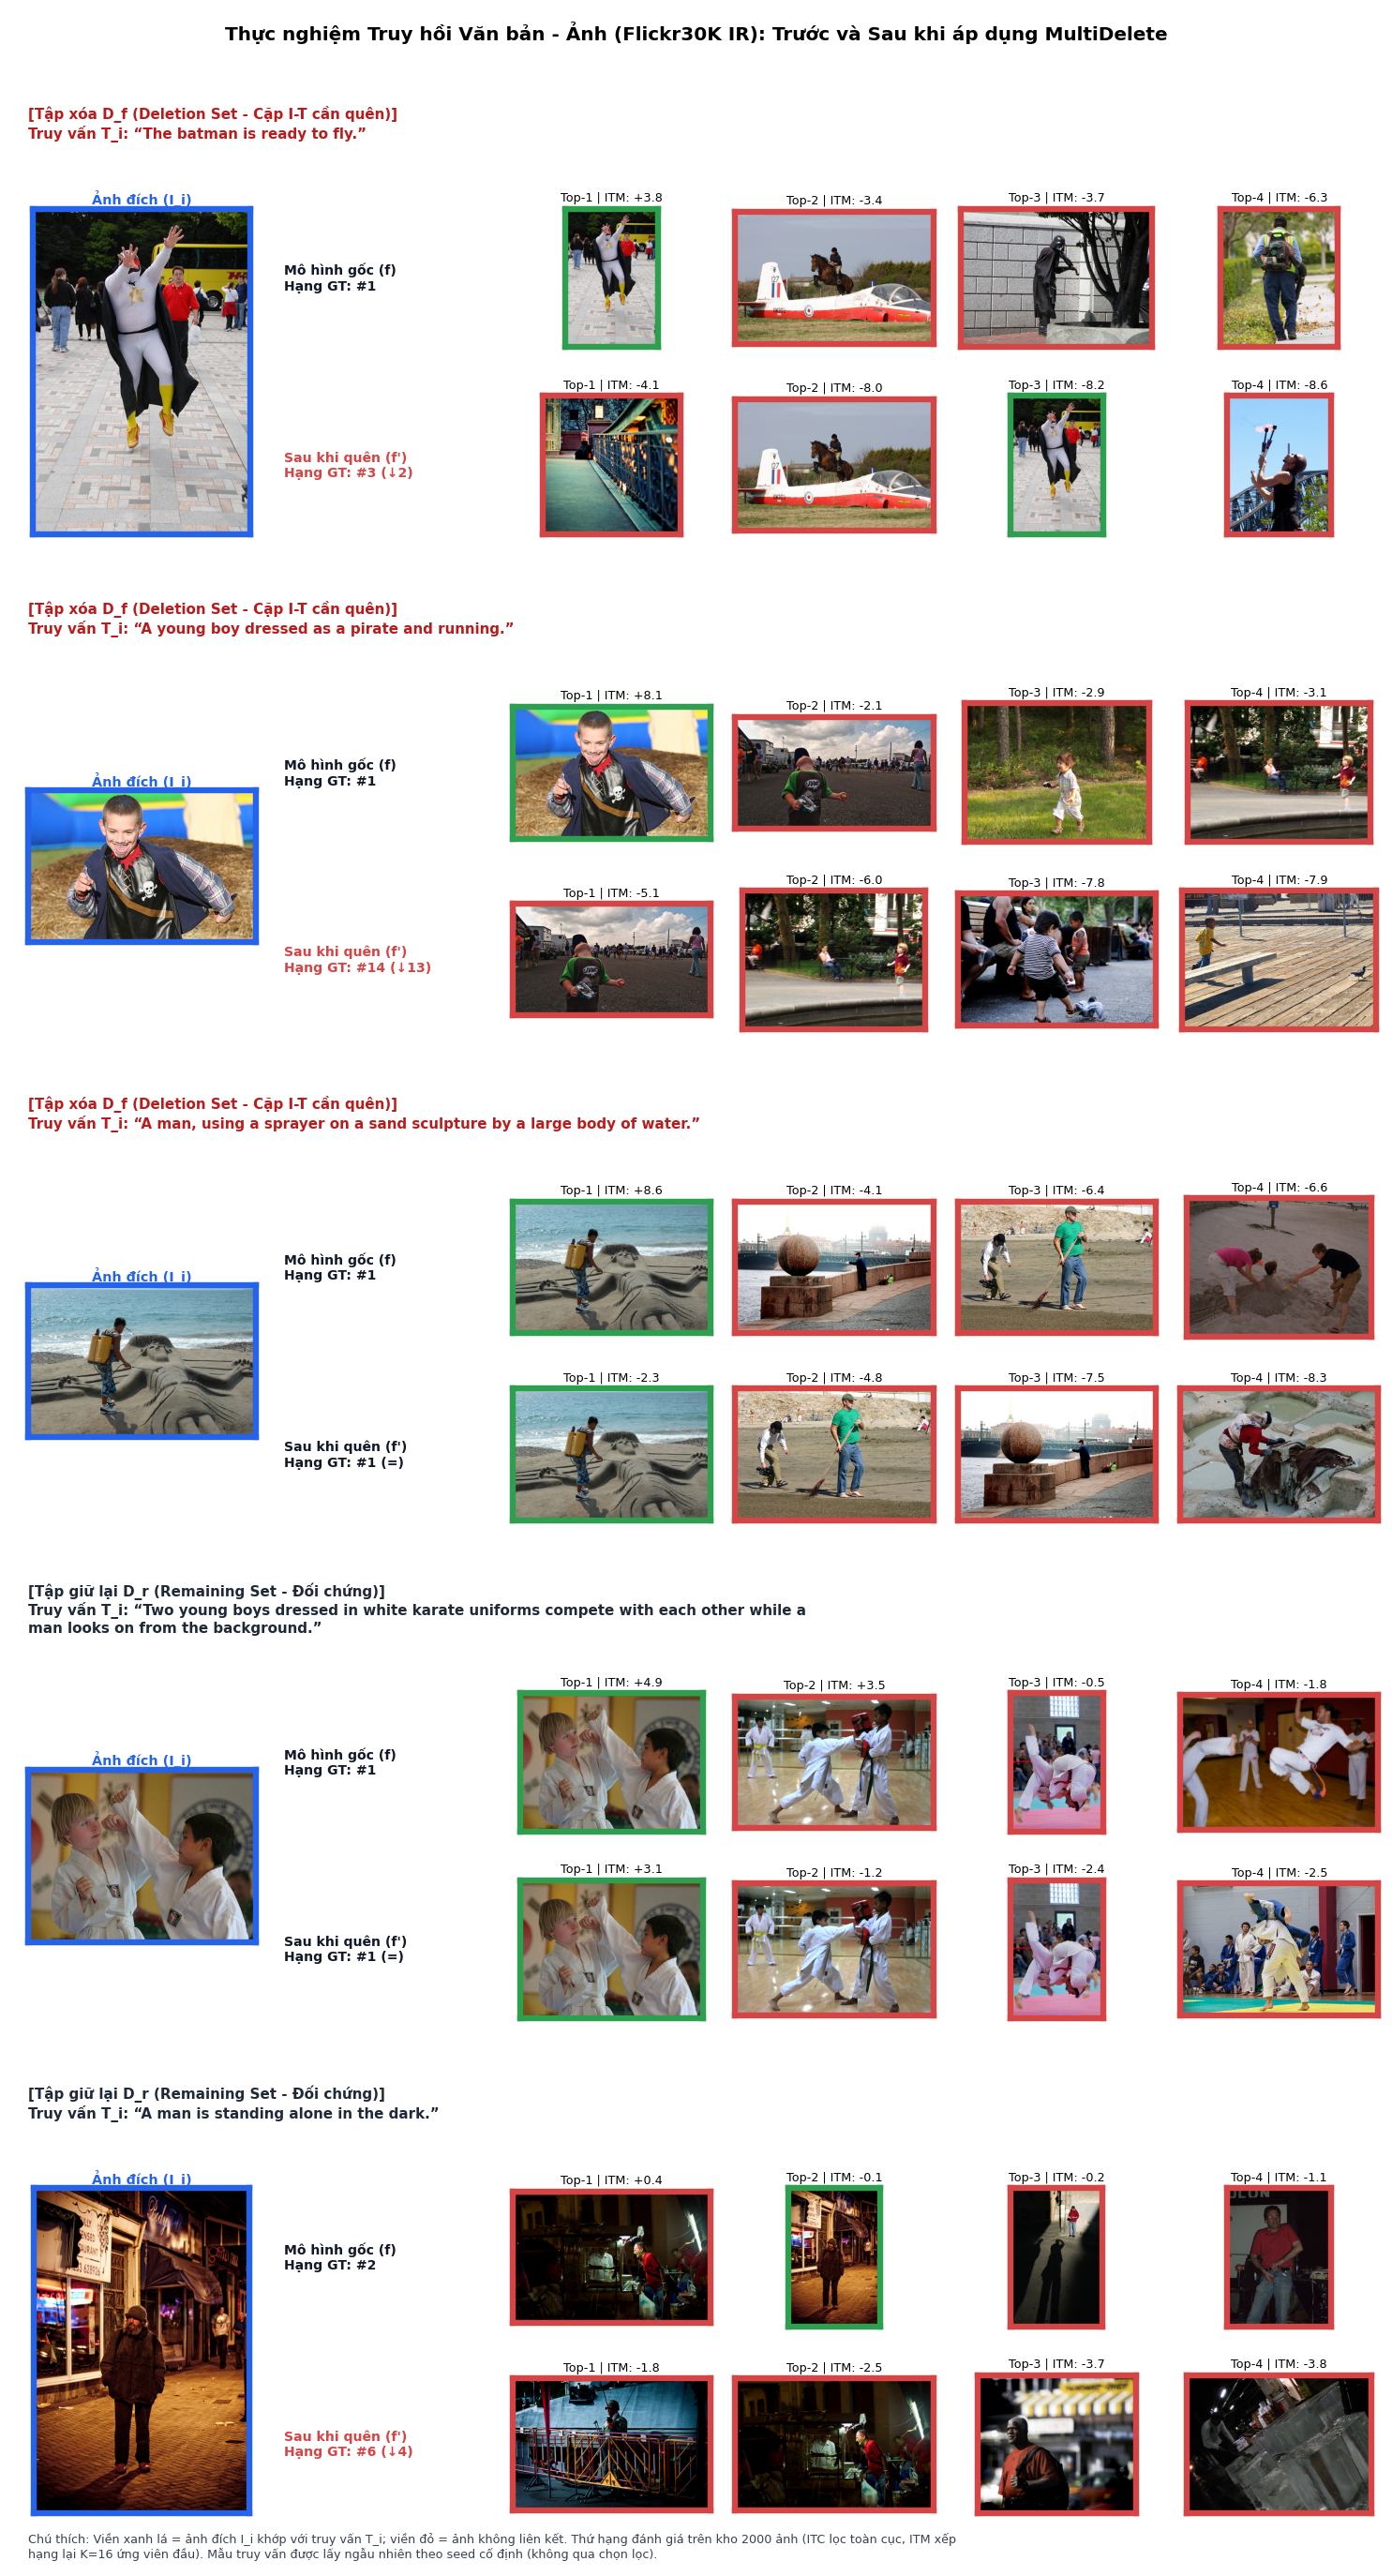

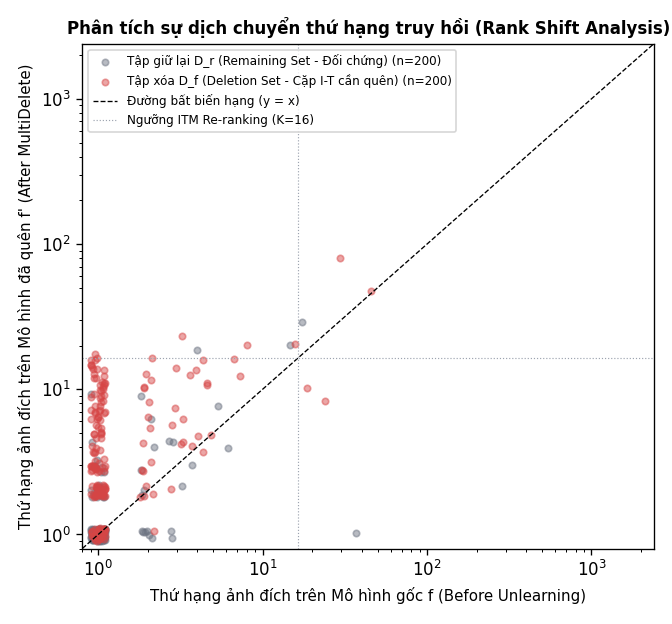


=== TỔNG HỢP ĐỘ ĐO ĐÁNH GIÁ TRUY HỒI VĂN BẢN - ẢNH (TEXT-TO-IMAGE RETRIEVAL) ===
Tập xóa D_f (Deletion Set)       | N=200  | R@1: 79.0% → 22.5% | R@5: 96.0% → 65.0% | Hạng trung vị: #1 → #3 | Tỷ lệ suy giảm hạng: 72.0%
Tập giữ lại D_r (Remaining Set)  | N=200  | R@1: 88.0% → 82.0% | R@5: 98.0% → 96.5% | Hạng trung vị: #1 → #1 | Tỷ lệ suy giảm hạng: 15.5%


In [12]:
import json
from IPython.display import display, Image as IPImage
D = f"{SAVE}/flickr30k/demo"
for f in (f"{D}/demo1.png", f"{D}/demo1_rank_shift.png"):
    if os.path.exists(f):
        display(IPImage(f))
if os.path.exists(f"{D}/demo1.json"):
    st = json.load(open(f"{D}/demo1.json", encoding="utf-8"))["stats"]
    print("\n=== TỔNG HỢP ĐỘ ĐO ĐÁNH GIÁ TRUY HỒI VĂN BẢN - ẢNH (TEXT-TO-IMAGE RETRIEVAL) ===")
    for g, name in (("df", "Tập xóa D_f (Deletion Set)"), ("dr", "Tập giữ lại D_r (Remaining Set)")):
        s = st[g]
        print(f"{name:<32} | N={s['n']:<4} | R@1: {s['R@1'][0]:.1f}% → {s['R@1'][1]:.1f}% | "
              f"R@5: {s['R@5'][0]:.1f}% → {s['R@5'][1]:.1f}% | "
              f"Hạng trung vị: #{s['hang_trung_vi'][0]:.0f} → #{s['hang_trung_vi'][1]:.0f} | "
              f"Tỷ lệ suy giảm hạng: {s['ti_le_tut_hang']:.1f}%")